# Notebook 1 — Data Preparation and GraphRAG
## PharmaGraph-OTC: Answering Drug-Safety Questions over Over-the-Counter Medicines — GraphRAG vs Vector RAG
**AIML506 · Course Assignment**

| | |
|---|---|
| **Dataset** | *Pharma-safe Index Dataset* (112 over-the-counter drugs sold in pharmacies in Yogyakarta, Indonesia; English and Indonesian versions) |
| **Authors** | Danny Sebastian, Restyandito, Justinus Putranto Agung Nugroho (Universitas Kristen Duta Wacana) |
| **Dataset DOI** | 10.17632/m78j7ctwhn.2 — https://data.mendeley.com/datasets/m78j7ctwhn/2 |
| **Data article** | *Structured Over-The-Counter Medicine Dataset to Improve the safety of Pharmaceuticals*, Data in Brief (2024), DOI 10.1016/j.dib.2024.110794 (CC BY) |
| **Licence** | CC BY per the data article — **confirm on the Mendeley record before submitting** |

**What this notebook does (Tasks 1-3):** data card + EDA → graph model → rule-based extraction from free text (side effects, contraindications, interactions)
→ load into Neo4j Aura → GraphRAG pipeline (entity linking, Cypher templates, optional Text2Cypher, grounded and cited answers, refusal).

**Run on Kaggle:** attach the dataset (the `english/csv` folder, or both folders) as an input, Internet on, GPU on, and three Kaggle Secrets:
`NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD`. **No credentials are written in this notebook.**

**Outputs used by notebooks 2 and 3:** `drug_records.json`, `rag_common.py`, `ps_vocab.py`, `graph_rag.py`, `schema_note.txt`, `build_costs_graph.json`.

> **Honest scope note.** The dataset is small (112 drugs) but relational (9 linked tables) and text-rich. The benchmark therefore contains ~34 questions
> whose gold answers are computed from the tables; conclusions are about *this* small curated corpus (see "threats to validity" in the report).
> This is an information-retrieval study, **not medical advice**.

*Lab references: the Ollama set-up and Neo4j connection cells follow the pattern of the course lab notebooks. AI-use statement: see the report appendix.*

In [1]:
# ---- install + imports + configuration -------------------------------------------------------------
!pip -q install neo4j rapidfuzz networkx 2>&1 | tail -1

import os, re, json, time, random, glob, shutil, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT = "/kaggle/working"; os.makedirs(OUT, exist_ok=True); os.chdir(OUT); os.makedirs(f"{OUT}/figures", exist_ok=True)

# ---------------- configuration (edit here) ----------------
WIPE_GRAPH = True                       # delete the existing graph before loading (makes the notebook re-runnable)
NEO4J_DB   = None                       # None = the instance's home database (Aura instances are usually NOT named "neo4j"); or set the name here
GEN_MODEL  = "qwen2.5:7b-instruct"      # generator (Q4 via Ollama); the same model is used in notebooks 2 and 3
FILES      = {}                         # optional override, e.g. {"drug": "/kaggle/input/.../english/csv/data-obat.csv", ...}
COLMAPS    = {}                         # optional override, e.g. {"drug": {"id": "id", "name": "nama_obat", ...}}
BUILD = {}                              # build-cost log -> saved at the end

## 0. Pipeline code written to disk
These cells write the shared module (`rag_common.py`: single prompt, answer schema, serialisation), the vocabularies used for text extraction (`ps_vocab.py`)
and the GraphRAG retriever (`graph_rag.py`) so later cells — and notebooks 2 and 3 — can `import` them. **Read `graph_rag.py` in the Task 3 section.**

In [2]:
%%writefile rag_common.py
"""Shared helpers for both RAG systems: Ollama client, ONE prompt template,
answer schema and row serialisation.  Keep this file identical in all notebooks:
the fairness of the GraphRAG vs Vector RAG comparison depends on it."""
import json
import os
import re
import subprocess
import time

import requests

OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://127.0.0.1:11434")
GEN_OPTIONS = {"temperature": 0.0, "seed": 42, "num_ctx": 8192, "num_predict": 400}
MAX_CONTEXT_CHARS = 8000          # same context budget for every system

SCHEMA_NOTE = (
    "The database covers 112 over-the-counter drugs sold in pharmacies in Yogyakarta, Indonesia. For each drug it holds only: "
    "name, disease category, indication, composition (ingredients with amounts), side effects, contraindications, "
    "drug interactions, dose (adult / children), usage rules, period of use and price per unit. "
    "It does NOT hold manufacturers, mechanisms of action, storage or shelf life, regulatory approval, clinical evidence, "
    "prescription-only drugs, or any drug that is not one of these products."
)


def set_schema_note(text):
    global SCHEMA_NOTE
    SCHEMA_NOTE = text


SYSTEM_PROMPT = """You are a careful assistant for questions about over-the-counter drugs in a small pharmacy database.
Answer ONLY from the numbered EVIDENCE items you are given.
Rules:
1. Never use outside knowledge. If the evidence does not contain the answer, set "answerable" to false and
   set "answer" to "The available data does not contain this information."
2. Cite the ids of the evidence items you used (for example G1 or V3) in "citations".
3. Be concise. List every item the question asks for. For counts, use the number stated in the evidence.
4. Do not give medical advice.
Reply with JSON only: {"answerable": true|false, "answer": "...", "citations": ["G1", ...]}"""

ANSWER_SCHEMA = {
    "type": "object",
    "properties": {
        "answerable": {"type": "boolean"},
        "answer": {"type": "string"},
        "citations": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["answerable", "answer", "citations"],
}

REFUSAL_RE = re.compile(
    r"(does not contain|do not contain|cannot (be )?answer|not (available|contained|included|provided|in the (data|evidence))"
    r"|no (information|evidence|data)|insufficient)", re.I)


# ----------------------------------------------------------------------------- Ollama
def ollama_up():
    try:
        return requests.get(OLLAMA_URL, timeout=2).status_code == 200
    except Exception:
        return False


def ensure_ollama(wait=90):
    """Start `ollama serve` in the background if it is not running."""
    if ollama_up():
        return True
    log = open("/kaggle/working/ollama.log" if os.path.isdir("/kaggle/working") else "ollama.log", "w")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=log)
    for _ in range(wait):
        if ollama_up():
            return True
        time.sleep(1)
    raise RuntimeError("Ollama server did not start - check ollama.log")


def pull(model):
    subprocess.run(["ollama", "pull", model], check=True)


def chat(model, system, user, schema=None, options=None, timeout=600):
    """One chat call. Returns text + latency + token counts."""
    opts = dict(GEN_OPTIONS)
    opts.update(options or {})
    payload = {"model": model, "stream": False, "options": opts,
               "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]}
    if schema is not None:
        payload["format"] = schema
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=timeout)
    r.raise_for_status()
    d = r.json()
    return {"text": d["message"]["content"], "latency_s": time.perf_counter() - t0,
            "prompt_tokens": d.get("prompt_eval_count"), "output_tokens": d.get("eval_count")}


# ----------------------------------------------------------------------------- prompt
def build_user_prompt(question, items, max_chars=None):
    """Numbered evidence block under a fixed character budget. Returns (prompt, ids_kept)."""
    max_chars = max_chars or MAX_CONTEXT_CHARS
    lines, kept, used = [], [], 0
    for it in items:
        line = f"[{it['id']}] {it['text']}"
        if used + len(line) + 1 > max_chars:
            break
        lines.append(line)
        kept.append(it["id"])
        used += len(line) + 1
    evidence = "\n".join(lines) if lines else "(no evidence retrieved)"
    prompt = f"DATA SCOPE: {SCHEMA_NOTE}\n\nEVIDENCE:\n{evidence}\n\nQUESTION: {question}"
    return prompt, kept


def parse_answer(text):
    try:
        d = json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text, re.S)
        try:
            d = json.loads(m.group(0)) if m else None
        except Exception:
            d = None
    if not isinstance(d, dict) or "answer" not in d:
        return {"answerable": not bool(REFUSAL_RE.search(text)), "answer": text.strip(),
                "citations": re.findall(r"\b[GV]\d+\b", text), "parse_ok": False}
    cits = d.get("citations") or []
    if not isinstance(cits, list):
        cits = [str(cits)]
    return {"answerable": bool(d.get("answerable", True)), "answer": str(d.get("answer", "")).strip(),
            "citations": [str(c).strip("[] ") for c in cits], "parse_ok": True}


def generate_answer(model, question, items, options=None):
    """The SAME generator call for every retrieval system."""
    prompt, kept = build_user_prompt(question, items)
    out = chat(model, SYSTEM_PROMPT, prompt, schema=ANSWER_SCHEMA, options=options)
    res = parse_answer(out["text"])
    res.update({"raw": out["text"], "gen_latency_s": out["latency_s"], "prompt_tokens": out["prompt_tokens"],
                "output_tokens": out["output_tokens"], "kept_ids": kept, "prompt_chars": len(prompt)})
    return res


# ----------------------------------------------------------------------------- data helpers
def _j(items, sep="; "):
    return sep.join(str(x) for x in items if str(x).strip())


def serialize_drug(rec):
    """One drug record -> one text document (all linked tables joined through the drug id)."""
    parts = [f"Drug: {rec['name']}", f"Disease category: {rec['category']}"]
    if rec.get("indication"):
        parts.append(f"Indication: {rec['indication']}")
    if rec.get("ingredients"):
        parts.append("Composition: " + _j(rec["ingredients"]))
    if rec.get("side_effects"):
        parts.append("Side effects: " + _j(rec["side_effects"]))
    if rec.get("contraindications"):
        parts.append("Contraindications: " + _j(rec["contraindications"]))
    if rec.get("interactions"):
        parts.append("Drug interactions: " + _j(rec["interactions"]))
    dose = [f"{k}: {rec[f'dose_{k}']}" for k in ("adult", "children", "other") if rec.get(f"dose_{k}")]
    if dose:
        parts.append("Dose - " + _j(dose))
    if rec.get("usage_rules"):
        parts.append("Usage rules: " + _j(rec["usage_rules"]))
    if rec.get("usage_period"):
        parts.append("Period of use: " + str(rec["usage_period"]))
    if rec.get("prices"):
        parts.append("Price: " + _j(f"{u} IDR {p}" for u, p in rec["prices"]))
    return ". ".join(p.rstrip(". ") for p in parts) + "."


def fact_chunks(rec):
    """Finer-grained chunks: one per aspect, each prefixed with the drug name. Returns [(aspect, text)]."""
    n = rec["name"]
    out = [("category", f"Drug: {n}. Disease category: {rec['category']}. Indication: {rec.get('indication', '')}")]
    if rec.get("ingredients"):
        out.append(("composition", f"Drug: {n}. Composition: {_j(rec['ingredients'])}"))
    if rec.get("side_effects"):
        out.append(("side_effects", f"Drug: {n}. Side effects: {_j(rec['side_effects'])}"))
    if rec.get("contraindications"):
        out.append(("contraindications", f"Drug: {n}. Contraindications: {_j(rec['contraindications'])}"))
    if rec.get("interactions"):
        out.append(("interactions", f"Drug: {n}. Drug interactions: {_j(rec['interactions'])}"))
    dose = [f"{k}: {rec[f'dose_{k}']}" for k in ("adult", "children", "other") if rec.get(f"dose_{k}")]
    use = (["Dose - " + _j(dose)] if dose else []) + (["Usage rules: " + _j(rec["usage_rules"])] if rec.get("usage_rules") else []) + \
          ([f"Period of use: {rec['usage_period']}"] if rec.get("usage_period") else [])
    if use:
        out.append(("usage", f"Drug: {n}. " + ". ".join(use)))
    if rec.get("prices"):
        out.append(("price", f"Drug: {n}. Price: " + _j(f"{u} IDR {p}" for u, p in rec["prices"])))
    return [(a, t.rstrip(".") + ".") for a, t in out]


def load_records(path):
    """drug_records.json written by notebook 1."""
    with open(path) as f:
        recs = json.load(f)
    for r in recs:
        r["prices"] = [tuple(x) for x in r.get("prices", [])]
    return recs

Writing rag_common.py


In [3]:
%%writefile ps_vocab.py
"""Controlled vocabularies used to turn free-text side-effect and contraindication sentences into
graph terms (rule-based extraction).  term -> regex searched in the lower-cased text.
Both the loader (notebook 1) and the question linker (graph_rag.py) use the SAME patterns."""
import re

SIDE_EFFECT_VOCAB = {
    "nausea": r"nause|\bmual",
    "vomiting": r"vomit|emesis|muntah",
    "diarrhea": r"diarrh|diare",
    "constipation": r"constipat|sembelit|konstipasi",
    "abdominal pain": r"abdominal pain|stomach pain|stomach ache|stomachache|gastric pain|epigastric|cramp|sakit perut|nyeri (perut|lambung)",
    "heartburn": r"heartburn|dyspeps|indigestion|gastric irritation|stomach irritation|gastritis|stomach upset|upset stomach",
    "bloating": r"bloat|flatul|kembung",
    "dizziness": r"dizz|vertigo|light ?headed|pusing",
    "drowsiness": r"drows|sleepi|somnolen|sedat|mengantuk|kantuk",
    "headache": r"headache|sakit kepala",
    "insomnia": r"insomnia|sleeplessness|sulit tidur|difficulty sleeping",
    "restlessness": r"nervous|restless|agitat|anxiety|gelisah|tremor|jitter",
    "palpitations": r"palpitat|tachycard|berdebar|rapid heart",
    "dry mouth": r"dry mouth|xerostom|mulut kering",
    "blurred vision": r"blurred vision|blurry vision|visual disturb|pandangan kabur",
    "urinary retention": r"urinary retention|difficulty urinat|sulit buang air kecil",
    "skin rash": r"rash|itch|prurit|urticaria|hives|skin reaction|ruam|gatal|erythema",
    "allergic reaction": r"allerg|hypersensitiv|anaphyla|angioedema|alergi",
    "bleeding": r"bleed|hemorrhag|haemorrhag|perdarahan",
    "liver damage": r"liver|hepat|\bhati\b",
    "kidney damage": r"kidney|renal|nephro|ginjal",
    "breathing difficulty": r"bronchospasm|breathing difficult|shortness of breath|wheez|sesak",
    "fatigue": r"fatigue|weakness|tiredness|\btired|lemas",
    "loss of appetite": r"appetite|anorexia|nafsu makan",
    "electrolyte imbalance": r"hypophosph|hypokal|hypernatr|electrolyte",
    "confusion": r"dementia|confusion|disorient",
    "sweating": r"sweat|berkeringat",
    "stomach ulcer": r"ulcer|tukak",
}

CONTRA_VOCAB = {
    "hypersensitivity": r"hypersens|allerg|alergi",
    "severe kidney disease": r"kidney|renal|ginjal",
    "severe liver disease": r"liver|hepat|\bhati\b",
    "pregnancy": r"pregnan|hamil",
    "breastfeeding": r"breast ?feed|lactat|menyusui|nursing",
    "young children": r"child|infant|neonat|\bbaby|babies|\banak|bayi|under \d+ ?(years?|months?)",
    "asthma": r"asthma|asma",
    "stomach ulcer": r"ulcer|peptic|tukak|maag",
    "digestive obstruction": r"obstruct|obstruksi|ileus",
    "heart disease": r"heart|cardi|jantung",
    "hypertension": r"hypertens|high blood pressure|hipertensi",
    "diabetes": r"diabet",
    "glaucoma": r"glaucoma|glaukoma",
    "enlarged prostate": r"prostat",
    "epilepsy": r"epilep|seizure|kejang",
    "MAO inhibitor use": r"\bmao\b|monoamine",
    "G6PD deficiency": r"g6pd",
    "bleeding disorders": r"coagul|hemophil|haemophil|thrombocyt|bleeding",
    "alcoholism": r"alcohol|alkohol",
}

_C_SE = {k: re.compile(v, re.I) for k, v in SIDE_EFFECT_VOCAB.items()}
_C_CO = {k: re.compile(v, re.I) for k, v in CONTRA_VOCAB.items()}


def extract_terms(text, kind="effect"):
    """Return the vocabulary terms whose pattern occurs in `text`."""
    comp = _C_SE if kind == "effect" else _C_CO
    t = str(text)
    return [term for term, rx in comp.items() if rx.search(t)]


def term_spans(text, kind="effect"):
    """(term, start, end) for every pattern hit in `text` (used by the question linker)."""
    comp = _C_SE if kind == "effect" else _C_CO
    out = []
    for term, rx in comp.items():
        for m in rx.finditer(text):
            out.append((term, m.start(), m.end()))
    return out

Writing ps_vocab.py


In [4]:
%%writefile graph_rag.py
"""GraphRAG retriever for the Pharma-safe Index graph in Neo4j Aura.
Entity linking (exact / alias / fuzzy + vocabulary terms) -> intent planning -> parameterised read-only
Cypher templates -> numbered evidence facts with provenance.  Optional Text2Cypher with validation."""
import re
import time

from rapidfuzz import fuzz, process

import ps_vocab as V
import rag_common as rc

NODE_TYPES = ("drug", "ingredient", "category", "unit")
TERM_TYPES = ("effect", "contra")
STOP = set("""the a an of in on for to is are was were what which who whom whose how many much does do did with and or by from as at
that this these those there their its it be can you me my tell give list name show drug drugs medicine medicines product products
category categories ingredient ingredients active side effect effects contain contains containing most top other same per price
dose doses used use usage take taken""".split())
NUM_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10}


def norm(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]", " ", str(s).lower())).strip()


# ============================================================================ entity linking
class EntityIndex:
    SPEC = {"drug": ("Drug", "name_key", "name"), "ingredient": ("Ingredient", "key", "name"),
            "category": ("Category", "key", "name"), "unit": ("Unit", "key", "name")}

    def __init__(self, driver=None, database=None):
        self.driver, self.db = driver, database
        self.maps = {t: {} for t in NODE_TYPES}      # normalised name -> (key, display)
        self.alias = {t: {} for t in NODE_TYPES}
        self.choices = {t: [] for t in NODE_TYPES}

    def load(self):
        with self.driver.session(database=self.db) as s:
            for t, (label, kp, npp) in self.SPEC.items():
                for r in s.run(f"MATCH (n:{label}) RETURN DISTINCT n.{kp} AS key, n.{npp} AS name").data():
                    if r["key"]:
                        self.maps[t].setdefault(norm(r["key"]), (r["key"], r["name"]))
        return self.finalise()

    def load_from_records(self, recs):
        """Offline construction (tests)."""
        for r in recs:
            self.maps["drug"].setdefault(norm(r["name_key"]), (r["name_key"], r["name"]))
            self.maps["category"].setdefault(norm(r["category_key"]), (r["category_key"], r["category"]))
            for k, n in zip(r["ingredient_keys"], r["ingredient_names"]):
                self.maps["ingredient"].setdefault(norm(k), (k, n))
            for u, _ in r["prices"]:
                self.maps["unit"].setdefault(norm(u), (u.lower(), u))
        return self.finalise()

    def finalise(self):
        for t in NODE_TYPES:
            self.choices[t] = list(self.maps[t].keys())
        for t in ("drug", "ingredient"):
            cand = {}
            for nm in self.choices[t]:
                toks = nm.split()
                if len(toks) < 2:
                    continue
                for a in {toks[0], " ".join(toks[:2])}:
                    if len(a) >= 5 and a not in STOP and a not in self.maps[t]:
                        cand.setdefault(a, set()).add(nm)
            self.alias[t] = {a: self.maps[t][list(v)[0]] for a, v in cand.items() if len(v) == 1}
        return {t: len(self.maps[t]) for t in NODE_TYPES}

    def link(self, question, fuzzy_cutoff=90):
        toks = norm(question).split()
        text = " ".join(toks)
        starts, pos = [], 0
        for t in toks:
            starts.append(pos)
            pos += len(t) + 1
        taken = [False] * len(toks)
        found = []

        def add(t, key, name, span, score, method):
            found.append({"type": t, "key": key, "name": name, "span": span, "score": score, "method": method})

        def mark(i, n):
            for j in range(i, i + n):
                taken[j] = True

        def scan(types, table, method, score, min_len=1):
            for n in range(min(7, len(toks)), 0, -1):
                for i in range(len(toks) - n + 1):
                    if any(taken[i:i + n]):
                        continue
                    span = " ".join(toks[i:i + n])
                    if n == 1 and (span in STOP or len(span) < max(3, min_len) or span.isdigit()):
                        continue
                    hits = [(t, table[t][span]) for t in types if span in table[t]]
                    if hits:
                        for t, (key, name) in hits:
                            add(t, key, name, span, score, method)
                        mark(i, n)

        scan(("drug", "ingredient"), self.maps, "exact", 100)                 # 1. names of drugs and ingredients
        # 1b. categories named explicitly (quoted, or next to the word 'category') win over vocabulary terms,
        #     so a category called 'diarrhea' is not mistaken for the side effect 'diarrhea'
        quoted = {norm(q) for q in re.findall(r"['\"]([^'\"]+)['\"]", question)}
        for n in range(min(4, len(toks)), 0, -1):
            for i in range(len(toks) - n + 1):
                if any(taken[i:i + n]):
                    continue
                span = " ".join(toks[i:i + n])
                if span in self.maps["category"]:
                    before = toks[i - 1] if i > 0 else ""
                    after = toks[i + n] if i + n < len(toks) else ""
                    if span in quoted or before in ("category", "categories") or after in ("category", "categories"):
                        key, name = self.maps["category"][span]
                        add("category", key, name, span, 100, "exact")
                        mark(i, n)
        # 2. vocabulary terms (side effects / contraindications) on the not-yet-used text
        masked = list(text)
        for i, t in enumerate(toks):
            if taken[i]:
                for k in range(starts[i], starts[i] + len(t)):
                    masked[k] = "#"
        masked = "".join(masked)
        for kind, label in (("effect", "effect"), ("contra", "contra")):
            seen = set()
            for term, a, b in V.term_spans(masked, kind):
                if term in seen:
                    continue
                seen.add(term)
                add(label, term, term, masked[a:b], 100, "vocab")
                for i, t in enumerate(toks):
                    if starts[i] < b and starts[i] + len(t) > a:
                        taken[i] = True
        scan(("category", "unit"), self.maps, "exact", 100)                  # 3. categories / price units
        scan(("drug", "ingredient"), self.alias, "alias", 95, 5)             # 4. unambiguous aliases
        for n in range(min(4, len(toks)), 0, -1):                            # 5. fuzzy (typos)
            for i in range(len(toks) - n + 1):
                if any(taken[i:i + n]):
                    continue
                span = " ".join(toks[i:i + n])
                if len(span) < 6 or all(w in STOP for w in toks[i:i + n]) or span.isdigit():
                    continue
                best = None
                for t in ("drug", "ingredient"):
                    if self.choices[t]:
                        m = process.extractOne(span, self.choices[t], scorer=fuzz.ratio, score_cutoff=fuzzy_cutoff)
                        if m and (best is None or m[1] > best[1]):
                            best = (t, m[1], m[0])
                if best:
                    t, sc, nm = best
                    key, name = self.maps[t][nm]
                    add(t, key, name, span, round(sc, 1), "fuzzy")
                    mark(i, n)
        return found


# ============================================================================ Cypher templates
def _ev(s, n=170):
    s = str(s or "")
    return s if len(s) <= n else s[:n - 3] + "..."


def count_fmt(template):
    return lambda r, c: (template.format(n=r["n"], **c), [])


def names_fmt(template):
    return lambda r, c: (template.format(name=r["name"], **c), [r["id"]])


CARD = """
MATCH (d:Drug {name_key:$dkey})
OPTIONAL MATCH (d)-[c:CONTAINS]->(i:Ingredient)
WITH d, collect(i.name + CASE WHEN coalesce(c.amount, '') = '' THEN '' ELSE ' ' + c.amount + ' ' + coalesce(c.unit, '') END) AS comp
OPTIONAL MATCH (d)-[s:SOLD_AS]->(u:Unit)
WITH d, comp, collect(u.name + ' IDR ' + toString(s.price)) AS prices
RETURN d.id AS id, d.name AS name, d.category AS category, d.indication AS indication, comp, prices,
       d.side_effects AS side_effects, d.contraindications AS contra, d.interactions AS interactions,
       d.dose_adult AS dose_adult, d.dose_children AS dose_children, d.dose_other AS dose_other,
       d.usage_rules AS usage_rules, d.usage_period AS usage_period
"""

TEMPLATES = {
    # ---- drug lists ------------------------------------------------------------------------------
    "drugs_with_ingredient": dict(
        cypher=("MATCH (:Ingredient {key:$ikey})<-[c:CONTAINS]-(d:Drug) RETURN d.id AS id, d.name AS name, c.amount AS amount, c.unit AS unit "
                "ORDER BY name LIMIT $limit"),
        count="MATCH (:Ingredient {key:$ikey})<-[:CONTAINS]-(d:Drug) RETURN count(DISTINCT d) AS n",
        count_text="{n} drugs contain the ingredient '{iname}'.",
        fmt=lambda r, c: (f"Drug '{r['name']}' contains '{c['iname']}' ({r['amount']} {r['unit']}).".replace("( ", "(").replace(" )", ")"), [r["id"]])),
    "shared_ingredient_drugs": dict(
        cypher=("MATCH (:Drug {name_key:$dkey})-[:CONTAINS]->(i:Ingredient)<-[:CONTAINS]-(o:Drug) WHERE o.name_key <> $dkey "
                "WITH o, collect(DISTINCT i.name) AS via RETURN o.id AS id, o.name AS name, via ORDER BY name LIMIT $limit"),
        fmt=lambda r, c: (f"Drug '{r['name']}' shares the ingredient(s) {', '.join(r['via'])} with '{c['dname']}'.", [r["id"]])),
    "drugs_in_category": dict(
        cypher="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug) RETURN d.id AS id, d.name AS name ORDER BY name LIMIT $limit",
        count="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug) RETURN count(DISTINCT d) AS n",
        count_text="{n} drugs belong to the category '{cname}'.",
        fmt=names_fmt("Drug '{name}' belongs to the category '{cname}'.")),
    "drugs_category_ingredient": dict(
        cypher=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTAINS]->(:Ingredient {key:$ikey}) "
                "RETURN DISTINCT d.id AS id, d.name AS name ORDER BY name LIMIT $limit"),
        count=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTAINS]->(:Ingredient {key:$ikey}) RETURN count(DISTINCT d) AS n"),
        count_text="{n} drugs in the category '{cname}' contain '{iname}'.",
        fmt=names_fmt("Drug '{name}' is in the category '{cname}' and contains '{iname}'.")),
    "drugs_with_effect": dict(
        cypher=("MATCH (:SideEffectTerm {key:$ekey})<-[r:MAY_CAUSE]-(d:Drug) RETURN d.id AS id, d.name AS name, r.evidence AS ev "
                "ORDER BY name LIMIT $limit"),
        count="MATCH (:SideEffectTerm {key:$ekey})<-[:MAY_CAUSE]-(d:Drug) RETURN count(DISTINCT d) AS n",
        count_text="{n} drugs list {ename} as a side effect.",
        fmt=lambda r, c: (f"Drug '{r['name']}' lists {c['ename']} as a side effect (source text: \"{_ev(r['ev'])}\").", [r["id"]])),
    "drugs_effect_category": dict(
        cypher=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[r:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) "
                "RETURN d.id AS id, d.name AS name, r.evidence AS ev ORDER BY name LIMIT $limit"),
        count=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) RETURN count(DISTINCT d) AS n"),
        count_text="{n} drugs in the category '{cname}' list {ename} as a side effect.",
        fmt=lambda r, c: (f"Drug '{r['name']}' (category '{c['cname']}') lists {c['ename']} as a side effect (source text: \"{_ev(r['ev'])}\").", [r["id"]])),
    "drugs_with_two_effects": dict(
        cypher=("MATCH (d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) MATCH (d)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey2}) "
                "RETURN DISTINCT d.id AS id, d.name AS name ORDER BY name LIMIT $limit"),
        count=("MATCH (d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) MATCH (d)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey2}) "
               "RETURN count(DISTINCT d) AS n"),
        count_text="{n} drugs list both {ename} and {ename2} as side effects.",
        fmt=names_fmt("Drug '{name}' lists both {ename} and {ename2} as side effects.")),
    "drugs_with_contra": dict(
        cypher=("MATCH (:ContraTerm {key:$kkey})<-[r:CONTRAINDICATED_IN]-(d:Drug) RETURN d.id AS id, d.name AS name, r.evidence AS ev "
                "ORDER BY name LIMIT $limit"),
        count="MATCH (:ContraTerm {key:$kkey})<-[:CONTRAINDICATED_IN]-(d:Drug) RETURN count(DISTINCT d) AS n",
        count_text="{n} drugs list {kname} as a contraindication.",
        fmt=lambda r, c: (f"Drug '{r['name']}' is contraindicated for: {c['kname']} (source text: \"{_ev(r['ev'])}\").", [r["id"]])),
    "drugs_contra_category": dict(
        cypher=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[r:CONTRAINDICATED_IN]->(:ContraTerm {key:$kkey}) "
                "RETURN d.id AS id, d.name AS name, r.evidence AS ev ORDER BY name LIMIT $limit"),
        count=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTRAINDICATED_IN]->(:ContraTerm {key:$kkey}) RETURN count(DISTINCT d) AS n"),
        count_text="{n} drugs in the category '{cname}' list {kname} as a contraindication.",
        fmt=lambda r, c: (f"Drug '{r['name']}' (category '{c['cname']}') is contraindicated for: {c['kname']} (source text: \"{_ev(r['ev'])}\").", [r["id"]])),
    "drugs_interaction_ingredient": dict(
        cypher=("MATCH (:Ingredient {key:$ikey})<-[:INVOLVES]-(x:Interaction)<-[:HAS_INTERACTION]-(d:Drug) "
                "WITH d, collect(x.text)[0] AS txt RETURN d.id AS id, d.name AS name, txt ORDER BY name LIMIT $limit"),
        count=("MATCH (:Ingredient {key:$ikey})<-[:INVOLVES]-(x:Interaction)<-[:HAS_INTERACTION]-(d:Drug) RETURN count(DISTINCT d) AS n"),
        count_text="{n} drugs have a documented interaction statement that mentions '{iname}'.",
        fmt=lambda r, c: (f"Drug '{r['name']}' has an interaction statement mentioning '{c['iname']}': \"{_ev(r['txt'])}\"", [r["id"]])),
    # ---- single-drug card (aspects chosen by the planner) --------------------------------------------
    "drug_card": dict(cypher=CARD, fmt=None),
    # ---- counts -----------------------------------------------------------------------------------
    "count_drugs_ingredient": dict(cypher="MATCH (:Ingredient {key:$ikey})<-[:CONTAINS]-(d:Drug) RETURN count(DISTINCT d) AS n",
                                   fmt=count_fmt("{n} drugs contain the ingredient '{iname}'.")),
    "count_drugs_category": dict(cypher="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug) RETURN count(DISTINCT d) AS n",
                                 fmt=count_fmt("{n} drugs belong to the category '{cname}'.")),
    "count_drugs_effect": dict(cypher="MATCH (:SideEffectTerm {key:$ekey})<-[:MAY_CAUSE]-(d:Drug) RETURN count(DISTINCT d) AS n",
                               fmt=count_fmt("{n} drugs list {ename} as a side effect.")),
    "count_drugs_contra": dict(cypher="MATCH (:ContraTerm {key:$kkey})<-[:CONTRAINDICATED_IN]-(d:Drug) RETURN count(DISTINCT d) AS n",
                               fmt=count_fmt("{n} drugs list {kname} as a contraindication.")),
    "count_drugs_effect_category": dict(
        cypher="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) RETURN count(DISTINCT d) AS n",
        fmt=count_fmt("{n} drugs in the category '{cname}' list {ename} as a side effect.")),
    "count_drugs_contra_category": dict(
        cypher="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTRAINDICATED_IN]->(:ContraTerm {key:$kkey}) RETURN count(DISTINCT d) AS n",
        fmt=count_fmt("{n} drugs in the category '{cname}' list {kname} as a contraindication.")),
    # ---- rankings -----------------------------------------------------------------------------------
    "rank_ingredients_by_drugs": dict(
        cypher=("MATCH (i:Ingredient)<-[:CONTAINS]-(d:Drug) WITH i, count(DISTINCT d) AS n ORDER BY n DESC, i.name "
                "RETURN i.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"The ingredient '{r['name']}' is used in {r['n']} drugs.", [])),
    "rank_categories_by_drugs": dict(
        cypher=("MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) WITH c, count(DISTINCT d) AS n ORDER BY n DESC, c.name "
                "RETURN c.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"The category '{r['name']}' contains {r['n']} drugs.", [])),
    "rank_effects_by_drugs": dict(
        cypher=("MATCH (t:SideEffectTerm)<-[:MAY_CAUSE]-(d:Drug) WITH t, count(DISTINCT d) AS n ORDER BY n DESC, t.name "
                "RETURN t.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"The side effect '{r['name']}' is listed by {r['n']} drugs.", [])),
    "rank_contra_by_drugs": dict(
        cypher=("MATCH (t:ContraTerm)<-[:CONTRAINDICATED_IN]-(d:Drug) WITH t, count(DISTINCT d) AS n ORDER BY n DESC, t.name "
                "RETURN t.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"The contraindication '{r['name']}' is listed by {r['n']} drugs.", [])),
    "rank_drugs_by_effects": dict(
        cypher=("MATCH (d:Drug)-[:MAY_CAUSE]->(t:SideEffectTerm) WITH d, count(DISTINCT t) AS n ORDER BY n DESC, d.name "
                "RETURN d.id AS id, d.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"Drug '{r['name']}' lists {r['n']} different side-effect terms.", [r["id"]])),
    "rank_drugs_by_ingredients": dict(
        cypher=("MATCH (d:Drug)-[:CONTAINS]->(i:Ingredient) WITH d, count(DISTINCT i) AS n ORDER BY n DESC, d.name "
                "RETURN d.id AS id, d.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"Drug '{r['name']}' contains {r['n']} different ingredients.", [r["id"]])),
    "rank_ingredients_in_category": dict(
        cypher=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTAINS]->(i:Ingredient) "
                "WITH i, count(DISTINCT d) AS n ORDER BY n DESC, i.name RETURN i.name AS name, n LIMIT $top"),
        fmt=lambda r, c: (f"In the category '{c['cname']}', the ingredient '{r['name']}' appears in {r['n']} drugs.", [])),
    "rank_drugs_by_price_high": dict(
        cypher=("MATCH (d:Drug)-[s:SOLD_AS]->(:Unit {key:$ukey}) WITH d, max(s.price) AS price ORDER BY price DESC, d.name "
                "RETURN d.id AS id, d.name AS name, price LIMIT $top"),
        fmt=lambda r, c: (f"Drug '{r['name']}' costs IDR {r['price']} per {c['uname']}.", [r["id"]])),
    "rank_drugs_by_price_low": dict(
        cypher=("MATCH (d:Drug)-[s:SOLD_AS]->(:Unit {key:$ukey}) WITH d, min(s.price) AS price ORDER BY price ASC, d.name "
                "RETURN d.id AS id, d.name AS name, price LIMIT $top"),
        fmt=lambda r, c: (f"Drug '{r['name']}' costs IDR {r['price']} per {c['uname']}.", [r["id"]])),
}


def card_facts(r, aspects):
    n, out = r["name"], []
    rid = [r["id"]]
    lines = lambda x: [s for s in (x or []) if str(s).strip()]
    for a in aspects:
        if a == "category":
            out.append((f"Drug '{n}' belongs to the disease category '{r['category']}'.", rid))
        elif a == "indication" and r.get("indication"):
            out.append((f"Indication of '{n}': {r['indication']}", rid))
        elif a == "ingredients" and r.get("comp"):
            out.append((f"'{n}' contains: {', '.join(x.strip() for x in r['comp'])}.", rid))
        elif a == "side_effects":
            out += [(f"Side effect statement for '{n}': {s}", rid) for s in lines(r.get("side_effects"))]
        elif a == "contra":
            out += [(f"Contraindication statement for '{n}': {s}", rid) for s in lines(r.get("contra"))]
        elif a == "interactions":
            out += [(f"Interaction statement for '{n}': {s}", rid) for s in lines(r.get("interactions"))]
        elif a == "dose":
            d = [f"{k}: {r[f'dose_{k}']}" for k in ("adult", "children", "other") if r.get(f"dose_{k}")]
            if d:
                out.append((f"Dose of '{n}' - " + "; ".join(d), rid))
        elif a == "usage":
            if lines(r.get("usage_rules")):
                out.append((f"Usage rules for '{n}': " + "; ".join(lines(r["usage_rules"])), rid))
            if r.get("usage_period"):
                out.append((f"Period of use for '{n}': {r['usage_period']}", rid))
        elif a == "price" and r.get("prices"):
            out.append((f"Price of '{n}': " + "; ".join(r["prices"]), rid))
    return out


def parse_top_n(ql, default=3):
    m = re.search(r"\b(?:top|first)\s+(\d+|" + "|".join(NUM_WORDS) + r")\b", ql)
    if not m:
        m = re.search(r"\b(\d+|" + "|".join(NUM_WORDS) + r")\s+(?:\w+\s+){0,2}(?:drugs|medicines|products|ingredients|categories|side effects|effects|contraindications)\b", ql)
    if m:
        v = m.group(1)
        return int(v) if v.isdigit() else NUM_WORDS[v]
    return default


# ============================================================================ retriever
class GraphRetriever:
    def __init__(self, driver, database=None, index=None):
        self.driver, self.db = driver, database
        self.index = index or EntityIndex(driver, database)

    # ---- resolve ambiguous links -----------------------------------------------------------------
    def resolve(self, question, links):
        ql = question.lower()
        contra_cue = re.search(r"contraindicat|should not (be )?(used|take|taken)|must not|avoid|not recommended|unsafe|cannot (use|take)|precaution|patients with|people with|suffering from|not be (used|given)", ql)
        effect_cue = re.search(r"side effect|adverse|\bcause|lead to|reaction", ql)
        eff = [l for l in links if l["type"] == "effect"]
        con = [l for l in links if l["type"] == "contra"]
        others = [l for l in links if l["type"] not in TERM_TYPES]
        if eff and con:
            if contra_cue and not effect_cue:
                eff = []
            elif effect_cue and not contra_cue:
                con = []
            elif not contra_cue and not effect_cue:
                con = []
        # a span matching both a drug and an ingredient: quoted -> drug, otherwise ingredient
        quoted = {norm(q) for q in re.findall(r"['\"]([^'\"]+)['\"]", question)}
        by_span, out = {}, []
        for l in others:
            by_span.setdefault(l["span"], []).append(l)
        for span, ls in by_span.items():
            types = {l["type"] for l in ls}
            if len(ls) > 1 and {"drug", "ingredient"} <= types:
                pref = "drug" if span in quoted else "ingredient"
                ls = [l for l in ls if l["type"] == pref]
            out += ls
        return out + eff + con

    # ---- planning -----------------------------------------------------------------------------------
    def plan(self, question, links):
        ql = question.lower()
        by = {t: [l for l in links if l["type"] == t] for t in NODE_TYPES + TERM_TYPES}
        D, I, C, U, E, K = (by[t] for t in ("drug", "ingredient", "category", "unit", "effect", "contra"))
        ctx = {"top": parse_top_n(ql), "limit": 10, "drugs": [(l["key"], l["name"]) for l in D[:3]]}
        for pre, lst, kk, nn in (("d", D, "dkey", "dname"), ("i", I, "ikey", "iname"), ("c", C, "ckey", "cname"),
                                 ("u", U, "ukey", "uname"), ("e", E, "ekey", "ename"), ("k", K, "kkey", "kname")):
            if lst:
                ctx[kk], ctx[nn] = lst[0]["key"], lst[0]["name"]
        if len(E) > 1:
            ctx["ekey2"], ctx["ename2"] = E[1]["key"], E[1]["name"]
        has = lambda pat: re.search(pat, ql) is not None
        how_many = has(r"\bhow many\b|\bnumber of\b|\bcount\b")
        ranking = has(r"\b(top|most|largest|highest|biggest|leading|rank|cheapest|lowest|least|expensive|priciest|pricey)\b")
        price_cue = has(r"\b(price|prices|cost|costs|costly|expensive|cheap|cheapest|priciest|pricey)\b")

        if ranking and not D:
            if U and price_cue:
                return (["rank_drugs_by_price_low"] if has(r"cheap|lowest|least") else ["rank_drugs_by_price_high"]), ctx
            if C and has(r"ingredient") and not I:
                return ["rank_ingredients_in_category"], ctx
            if has(r"(drugs|medicines|products)\b.*\b(most|highest number of|largest number of)\b.*\bingredients"):
                return ["rank_drugs_by_ingredients"], ctx
            if has(r"side effects?|adverse"):
                return (["rank_drugs_by_effects"] if has(r"\bwhich (\d+ |top |the |three |five )?(drugs|medicines|products)") else ["rank_effects_by_drugs"]), ctx
            if has(r"contraindication"):
                return ["rank_contra_by_drugs"], ctx
            if has(r"ingredient"):
                return ["rank_ingredients_by_drugs"], ctx
            if has(r"categor"):
                return ["rank_categories_by_drugs"], ctx
        if how_many and not D:
            if E and C:
                return ["count_drugs_effect_category"], ctx
            if K and C:
                return ["count_drugs_contra_category"], ctx
            if E:
                return ["count_drugs_effect"], ctx
            if K:
                return ["count_drugs_contra"], ctx
            if I:
                return ["count_drugs_ingredient"], ctx
            if C:
                return ["count_drugs_category"], ctx
        if len(E) >= 2 and not D:
            return ["drugs_with_two_effects"], ctx
        if I and not D and has(r"interact"):
            return ["drugs_interaction_ingredient"], ctx
        if not D:
            if C and E:
                return ["drugs_effect_category"], ctx
            if C and K:
                return ["drugs_contra_category"], ctx
            if C and I:
                return ["drugs_category_ingredient"], ctx
            if E:
                return ["drugs_with_effect"], ctx
            if K:
                return ["drugs_with_contra"], ctx
        if D:
            if has(r"same (active )?ingredient|shar(e|es|ed)\b|similar|alternative|substitute|other (drugs|medicines|products)|also contain"):
                return ["shared_ingredient_drugs"], ctx
            asp = []
            cues = [("price", r"\b(price|prices|cost|costs|how much)\b"), ("dose", r"\b(dose|doses|dosage|how many (tablets|capsules|spoons))\b"),
                    ("side_effects", r"side effect|adverse"), ("contra", r"contraindicat|should not|must not|avoid|precaution"),
                    ("interactions", r"interact"), ("usage", r"how (to|should)|usage|instruction|rules|period|duration|how long|when to"),
                    ("ingredients", r"contain|ingredient|composition|active|made of"), ("category", r"categor|type of (illness|disease)|disease"),
                    ("indication", r"indication|used for|treat|purpose|what is .* for")]
            for a, pat in cues:
                if has(pat):
                    asp.append(a)
            if has(r"overview|describe|description|profile|summar|tell me about|everything"):
                asp = ["category", "indication", "ingredients", "side_effects", "contra", "price"]
            ctx["aspects"] = asp or ["category", "indication", "ingredients", "price"]
            return ["drug_card"], ctx
        if I:
            return ["drugs_with_ingredient"], ctx
        if C and has(r"overview|describe|summar|profile|tell me about"):
            return ["rank_ingredients_in_category", "drugs_in_category"], ctx
        if C:
            return ["drugs_in_category"], ctx
        return [], ctx

    # ---- execution ------------------------------------------------------------------------------------
    def _run(self, cypher, params):
        with self.driver.session(database=self.db) as s:
            return s.execute_read(lambda tx: tx.run(cypher, **params).data())

    def run_template(self, intent, ctx):
        t = TEMPLATES[intent]
        facts = []
        if intent == "drug_card":
            for dkey, dname in ctx["drugs"]:
                rows = self._run(t["cypher"], {**ctx, "dkey": dkey})
                for r in rows:
                    facts += [{"text": a, "row_ids": b} for a, b in card_facts(r, ctx["aspects"])]
            return facts, t["cypher"], len(facts)
        if "count" in t:
            rows = self._run(t["count"], ctx)
            if rows:
                facts.append({"text": t["count_text"].format(n=rows[0]["n"], **ctx), "row_ids": []})
        rows = self._run(t["cypher"], ctx)
        for r in rows:
            text, rids = t["fmt"](r, ctx)
            facts.append({"text": text, "row_ids": list(rids or [])})
        return facts, t["cypher"], len(rows)

    def retrieve_template(self, question, k=10):
        t0 = time.perf_counter()
        links = self.resolve(question, self.index.link(question))
        t_link = time.perf_counter() - t0
        intents, ctx = self.plan(question, links)
        facts, cyphers, nrec = [], [], 0
        for it in intents:
            f, cy, n = self.run_template(it, ctx)
            facts += f
            cyphers.append(cy)
            nrec += n
        items = [{"id": f"G{i + 1}", "text": f["text"], "row_ids": f["row_ids"], "kind": "graph_fact"} for i, f in enumerate(facts[:k])]
        if intents and not items:
            items = [{"id": "G1", "text": "The graph query returned no matching records.", "row_ids": [], "kind": "graph_fact"}]
        return {"items": items, "links": links, "intents": intents, "cypher": cyphers, "mode": "template",
                "retrieval_latency_s": time.perf_counter() - t0, "linking_latency_s": t_link, "n_records": nrec}

    # ---- Text2Cypher (read-only, validated) -------------------------------------------------------------
    SCHEMA_TEXT = """Node labels and properties:
(:Drug {id:int, name:str, name_key:str, category:str, indication:str, dose_adult:str, dose_children:str, usage_period:str,
        side_effects:[str], contraindications:[str], interactions:[str], usage_rules:[str], text:str})
(:Category {key:str, name:str})
(:Ingredient {key:str, name:str})
(:SideEffectTerm {key:str, name:str})        // e.g. 'drowsiness', 'nausea', 'headache'
(:ContraTerm {key:str, name:str})            // e.g. 'pregnancy', 'asthma', 'severe kidney disease'
(:Interaction {id:int, text:str})
(:Unit {key:str, name:str})                  // price unit, e.g. 'strip', 'box', 'bottle'
Relationships:
(:Drug)-[:IN_CATEGORY]->(:Category)
(:Drug)-[:CONTAINS {amount:str, unit:str}]->(:Ingredient)
(:Drug)-[:MAY_CAUSE {evidence:str}]->(:SideEffectTerm)
(:Drug)-[:CONTRAINDICATED_IN {evidence:str}]->(:ContraTerm)
(:Drug)-[:HAS_INTERACTION]->(:Interaction)-[:INVOLVES]->(:Ingredient)
(:Drug)-[:SOLD_AS {price:int}]->(:Unit)          // price in IDR
(:Drug)-[:SHARES_INGREDIENT {n:int}]-(:Drug)
Notes: `key` and `name_key` are lower-case names; names are in English."""

    T2C_SYSTEM = ("You translate questions into ONE read-only Neo4j Cypher query for the schema below. Return only the Cypher, no explanation, "
                  "no markdown. Use only MATCH/OPTIONAL MATCH/WITH/WHERE/RETURN/ORDER BY/LIMIT/UNWIND. Match entities by lower-case key "
                  "(e.g. {key:'paracetamol'}). Always return readable names and counts.\n\n" + SCHEMA_TEXT +
                  "\n\nExamples:\nQ: How many drugs contain paracetamol?\n"
                  "A: MATCH (:Ingredient {key:'paracetamol'})<-[:CONTAINS]-(d:Drug) RETURN count(DISTINCT d) AS n\n"
                  "Q: Which drugs list drowsiness as a side effect?\n"
                  "A: MATCH (:SideEffectTerm {key:'drowsiness'})<-[:MAY_CAUSE]-(d:Drug) RETURN DISTINCT d.name AS name ORDER BY name LIMIT 50\n"
                  "Q: Which 3 categories have the most drugs?\n"
                  "A: MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) RETURN c.name AS name, count(d) AS n ORDER BY n DESC LIMIT 3")

    FORBIDDEN = re.compile(r"\b(CREATE|MERGE|DELETE|DETACH|SET|REMOVE|DROP|LOAD|FOREACH|APOC|DBMS|GRANT|DENY|REVOKE|CALL|INDEX|CONSTRAINT)\b", re.I)

    @classmethod
    def validate_cypher(cls, q):
        q = re.sub(r"^```(?:cypher)?|```$", "", q.strip(), flags=re.M).strip().rstrip(";").strip()
        if not q:
            return None, "empty query"
        if ";" in q:
            return None, "multiple statements"
        if not re.match(r"^(MATCH|OPTIONAL MATCH|WITH|UNWIND)\b", q, re.I):
            return None, "must start with MATCH/WITH/UNWIND"
        if cls.FORBIDDEN.search(q):
            return None, f"forbidden keyword: {cls.FORBIDDEN.search(q).group(1)}"
        if not re.search(r"\bRETURN\b", q, re.I):
            return None, "no RETURN"
        if not re.search(r"\bLIMIT\b", q, re.I):
            q += " LIMIT 50"
        return q, None

    def text2cypher(self, question, model):
        out = rc.chat(model, self.T2C_SYSTEM, f"Q: {question}\nA:", schema=None, options={"num_predict": 250})
        q, err = self.validate_cypher(out["text"])
        return q, err, out

    def retrieve_text2cypher(self, question, model, k=10):
        t0 = time.perf_counter()
        q, err, out = self.text2cypher(question, model)
        items, rows, status = [], [], "ok"
        if err:
            status = f"invalid: {err}"
        else:
            try:
                self._run("EXPLAIN " + q, {})
                rows = self._run(q, {})
            except Exception as e:                    # noqa: BLE001
                status = f"error: {str(e)[:160]}"
        for i, r in enumerate(rows[:k]):
            rid = r.get("id")
            items.append({"id": f"G{i + 1}", "text": "Result row: " + "; ".join(f"{a}={b}" for a, b in r.items()),
                          "row_ids": [rid] if isinstance(rid, int) else [], "kind": "graph_row"})
        return {"items": items, "links": [], "intents": ["text2cypher"], "cypher": [q], "mode": "text2cypher", "status": status, "rows": rows,
                "retrieval_latency_s": time.perf_counter() - t0, "llm_latency_s": out["latency_s"], "n_records": len(rows)}

    def retrieve_hybrid(self, question, model, k=10):
        r = self.retrieve_template(question, k)
        if (not r["items"]) or r["items"][0]["text"].startswith("The graph query returned no"):
            r2 = self.retrieve_text2cypher(question, model, k)
            r2["links"], r2["mode"] = r["links"], "hybrid(text2cypher)"
            r2["retrieval_latency_s"] += r["retrieval_latency_s"]
            return r2
        r["mode"] = "hybrid(template)"
        return r

    def retrieve(self, question, k=10, mode="template", model=None):
        if mode == "template":
            return self.retrieve_template(question, k)
        if mode == "text2cypher":
            return self.retrieve_text2cypher(question, model, k)
        if mode == "hybrid":
            return self.retrieve_hybrid(question, model, k)
        raise ValueError(mode)

Writing graph_rag.py


## Task 1 — Problem and data understanding
**Domain.** Self-medication safety information for over-the-counter (OTC) drugs.
**Users.** Pharmacy students, pharmacists and public-health researchers who need quick, *grounded* answers.
**Questions people ask.** *What does drug X contain? Which other drugs share an ingredient with X? Which drugs in the "cough" category cause drowsiness?
Which drugs should not be used in pregnancy? Which drug interacts with ingredient Y? How many drugs list headache as a side effect? What precautions apply to X?*

**Why a graph?** The nine CSV tables are linked through the drug id and the free-text fields (side effects, contraindications, interactions) mention *shared concepts*
(symptoms, conditions, ingredients). Extracting those concepts turns text into relationships that support multi-hop and aggregation questions.

**Out of scope on purpose.** The data has **no manufacturer, mechanism of action, storage, shelf life, regulatory status or prescription drugs** — those questions are
*unanswerable* and test whether a system declines instead of guessing.

In [5]:
import json
import os
import re
from collections import Counter, defaultdict

import pandas as pd

import ps_vocab as V

# ----------------------------------------------------------------------------- 1. find the nine CSV files
ROLE_PATTERNS = [   # most specific first; matched on the lower-cased file name
    ("inter", r"interak|interaction"), ("side", r"efek|side"), ("contra", r"kontra|contra"),
    ("comp", r"kompos|composition"), ("price", r"harga|price"), ("dose", r"dosis|dose"),
    ("rule", r"aturan|rule"), ("period", r"jangka|period"), ("drug", r"obat|drug")]


def discover(paths):
    """role -> path. Prefers files inside an 'english' folder; falls back to any."""
    found = defaultdict(list)
    for p in paths:
        if not p.lower().endswith(".csv"):
            continue
        base = os.path.basename(p).lower()
        for role, pat in ROLE_PATTERNS:
            if re.search(pat, base):
                found[role].append(p)
                break
    pick = {}
    for role, ps in found.items():
        eng = [p for p in ps if "english" in p.lower() or "/en/" in p.lower()]
        pick[role] = sorted(eng or ps)[0]
    return pick


def read_csv_robust(p):
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            return pd.read_csv(p, dtype=str, keep_default_na=False, encoding=enc)
        except UnicodeDecodeError:
            continue
        except pd.errors.ParserError:
            return pd.read_csv(p, dtype=str, keep_default_na=False, encoding=enc, engine="python", on_bad_lines="skip")
    raise RuntimeError(f"cannot read {p}")


# ----------------------------------------------------------------------------- 2. column detection -> canonical names
SYN = {   # role -> canonical column -> candidate (compact, lower-case) substrings, tried in order
    "drug": {"id": ["id"], "name": ["namaobat", "drugname", "nameofdrug", "name"], "category": ["kategoripenyakit", "diseasecategory", "category", "kategori"],
             "indication": ["indikasi", "indication"]},
    "rule": {"text": ["aturanpakai", "usagerule", "usagerules", "rule", "aturan"]},
    "dose": {"profile": ["profil", "profile"], "dose": ["dosis", "dose"]},
    "side": {"text": ["efeksamping", "sideeffect", "effect"]},
    "price": {"unit": ["satuan", "unit", "bentukdosis", "form"], "price": ["harga", "price"]},
    "inter": {"text": ["interaksiobat", "druginteraction", "interaction", "interaksi"]},
    "period": {"text": ["jangkawaktupenggunaan", "usageperiod", "usagedperiod", "period", "jangka"]},
    "comp": {"name": ["namakomposisi", "namabahan", "kandungan", "komposisi", "zataktif", "bahanaktif", "bahan", "ingredient", "composition", "compound",
                      "substance", "component", "nama", "name"], "amount": ["jumlah", "amount", "quantity"], "unit": ["satuan", "unit"]},
    "contra": {"text": ["kontraindikasi", "contraindication", "contra"]},
}
FK_CANDIDATES = ["idobat", "drugid", "iddrug", "obatid", "id"]


def compact(c):
    return re.sub(r"[^a-z]", "", c.lower())


def detect_columns(role, df):
    cols = list(df.columns)
    comp = {c: compact(c) for c in cols}
    used, out = set(), {}
    if role != "drug":                                          # foreign key to the drug table
        for cand in FK_CANDIDATES:
            hit = next((c for c in cols if comp[c] == cand), None) or next((c for c in cols if cand in comp[c] and "id" in comp[c]), None)
            if hit:
                out["drug_id"] = hit
                used.add(hit)
                break
    for canon, cands in SYN[role].items():
        pick = None
        for cand in cands:                                      # exact compact match first, then substring
            pick = next((c for c in cols if c not in used and comp[c] == cand), None)
            if pick:
                break
        if pick is None:
            for cand in cands:
                pick = next((c for c in cols if c not in used and cand in comp[c]), None)
                if pick:
                    break
        if pick:
            out[canon] = pick
            used.add(pick)
    return _repair_text_columns(role, df, out, used)


TEXT_CANON = {"name", "text", "indication", "category", "profile", "dose"}


def _fill(series):
    s = series.map(clean_text)
    return float((s != "").mean()) if len(s) else 0.0


def _alpha(series):
    s = series.map(clean_text)
    s = s[s != ""]
    if s.empty:
        return 0.0
    return float(s.map(lambda x: sum(ch.isalpha() for ch in x) / max(1, len(x))).mean())


def _repair_text_columns(role, df, out, used):
    """If a text field was mapped to a (nearly) empty column, or not mapped at all, pick the unused column that really holds text."""
    for canon in SYN[role]:
        if canon not in TEXT_CANON:
            continue
        cur = out.get(canon)
        if cur is not None and _fill(df[cur]) >= 0.3:
            continue
        cands = [c for c in df.columns if c not in used and _fill(df[c]) >= 0.5 and _alpha(df[c]) >= 0.5]
        if not cands:
            continue
        best = max(cands, key=lambda c: (_fill(df[c]), _alpha(df[c])))
        print(f"   [auto-repair] {role}.{canon}: {'column ' + repr(cur) + ' is empty' if cur else 'no header matched'} -> using column {best!r}")
        if cur is not None:
            used.discard(cur)
        out[canon] = best
        used.add(best)
    return out


def norm_id(x):
    """'1', '1.0', ' 001 ' -> '1'; non-numeric ids (e.g. 'OBT-01') are only stripped and lower-cased."""
    s = clean_text(x)
    if re.fullmatch(r"\d+(\.0+)?", s):
        return str(int(float(s)))
    return s.lower()


def canonicalise(role, df, colmap):
    inv = {v: k for k, v in colmap.items()}
    out = df.rename(columns=inv)[[k for k in colmap]].copy()
    for c in out.columns:
        out[c] = out[c].map(clean_text)
    for c in ("id", "drug_id"):
        if c in out.columns:
            out[c] = out[c].map(norm_id)
    return out


def clean_text(s):
    if s is None or (isinstance(s, float) and pd.isna(s)):
        return ""
    s = str(s).replace("\u00a0", " ").replace("\\'", "'").replace('\\"', '"')
    return re.sub(r"\s+", " ", s).strip()


# ----------------------------------------------------------------------------- 3. JSON fallback
def _ck(k):
    return re.sub(r"[^a-z]", "", str(k).lower())


def jget(d, cands):
    """Value of the first key of dict d whose compact name equals (preferred) or contains one of the candidate names."""
    if not isinstance(d, dict):
        return None
    keys = {k: _ck(k) for k in d}
    for c in cands:
        for k, ck in keys.items():
            if ck == c and d[k] not in (None, ""):
                return d[k]
    for c in cands:
        for k, ck in keys.items():
            if c in ck and d[k] not in (None, ""):
                return d[k]
    return None


def _as_list(x):
    return x if isinstance(x, list) else ([] if x in (None, "") else [x])


def _text_of(x):
    """A statement can be a string, a number, or a small dict -> first string value."""
    if isinstance(x, dict):
        return next((str(v) for v in x.values() if isinstance(v, str) and v.strip()), "")
    return str(x)


def describe_json(path, n=1):
    data = json.load(open(path, encoding="utf-8"))
    if isinstance(data, dict):
        data = next((v for v in data.values() if isinstance(v, list)), [data])
    return json.dumps(data[:n], ensure_ascii=False, indent=1)[:2500]


def load_json_tables(path):
    """Same canonical frames from the dataset's JSON file. Key names are discovered, not assumed."""
    data = json.load(open(path, encoding="utf-8"))
    if isinstance(data, dict):                                  # e.g. {"drugs": [...]}
        data = next((v for v in data.values() if isinstance(v, list)), [])
    data = [d for d in data if isinstance(d, dict)]
    T = defaultdict(list)
    for i, d in enumerate(data, start=1):
        did = str(i)
        T["drug"].append({"id": did, "name": clean_text(jget(d, ["drugname", "namaobat", "nameofdrug", "name", "nama"]) or ""),
                          "category": clean_text(jget(d, ["diseasecategory", "kategoripenyakit", "category", "kategori"]) or ""),
                          "indication": clean_text(" ".join(_text_of(x) for x in _as_list(jget(d, ["indication", "indikasi"]))))})
        for pr in _as_list(jget(d, ["price", "harga"])):
            if isinstance(pr, dict):
                T["price"].append({"drug_id": did, "unit": clean_text(jget(pr, SYN["price"]["unit"]) or ""), "price": clean_text(jget(pr, SYN["price"]["price"]) or "")})
        for c in _as_list(jget(d, ["composition", "komposisi", "kandungan", "ingredient"])):
            if isinstance(c, dict):
                amount_k = jget(c, SYN["comp"]["amount"]); unit_k = jget(c, SYN["comp"]["unit"])
                name = jget(c, SYN["comp"]["name"])
                if name is None:                                # unknown key: first text value that is not the amount/unit
                    name = next((v for v in c.values() if isinstance(v, str) and re.search(r"[A-Za-z]{3,}", v) and v not in (unit_k, amount_k)), "")
                T["comp"].append({"drug_id": did, "name": clean_text(name), "amount": clean_text(amount_k or ""), "unit": clean_text(unit_k or "")})
            elif isinstance(c, str):                            # "Aluminium Hydroxide 200 mg"
                m = re.match(r"^(.*?)[\s:,-]*(\d+[.,]?\d*)\s*([a-zA-Z%]+)?$", c.strip())
                T["comp"].append({"drug_id": did, "name": clean_text(m.group(1) if m else c), "amount": m.group(2) if m else "", "unit": (m.group(3) or "") if m else ""})
        for role, cands in (("side", ["sideeffect", "efeksamping"]), ("contra", ["contraindication", "kontraindikasi"]),
                            ("inter", ["druginteraction", "interaksiobat", "interaction", "interaksi"]), ("rule", ["usagerule", "aturanpakai", "rule", "aturan"]),
                            ("period", ["usageperiod", "usagedperiod", "jangkawaktu", "period", "jangka"])):
            for t in _as_list(jget(d, cands)):
                if _text_of(t).strip():
                    T[role].append({"drug_id": did, "text": _text_of(t)})
        dose = jget(d, ["dosage", "dose", "dosis"])
        if isinstance(dose, dict):
            for k, v in dose.items():
                T["dose"].append({"drug_id": did, "profile": str(k), "dose": _text_of(v)})
        elif isinstance(dose, list):
            for x in dose:
                if isinstance(x, dict):
                    T["dose"].append({"drug_id": did, "profile": str(jget(x, ["profile", "profil"]) or ""), "dose": str(jget(x, ["dose", "dosis"]) or _text_of(x))})
        elif isinstance(dose, str):
            T["dose"].append({"drug_id": did, "profile": "adult", "dose": dose})
    return {k: pd.DataFrame(v) for k, v in T.items()}


# ----------------------------------------------------------------------------- 4. normalisation helpers
ING_ALIASES = {"aluminium": "aluminum", "acetaminophen": "paracetamol", "sulphate": "sulfate", "hydrochloride": "hcl"}


def key_of(s):
    s = re.sub(r"[^a-z0-9 ]", " ", clean_text(s).lower())
    s = " ".join(ING_ALIASES.get(w, w) for w in s.split())
    return s


def parse_price(s):
    s = clean_text(s)
    if re.fullmatch(r"\d{1,3}([.,]\d{3})+", s):                 # Indonesian thousands separator: 2.000 / 16,000
        return int(re.sub(r"[.,]", "", s))
    try:
        return int(round(float(s.replace(",", "."))))
    except ValueError:
        digits = re.sub(r"\D", "", s)
        return int(digits) if digits else None


def split_items(text):
    """A cell can hold several statements separated by newlines or ' | '."""
    parts = re.split(r"\s*\|\s*|\n", str(text))
    return [clean_text(p) for p in parts if clean_text(p)]


# ----------------------------------------------------------------------------- 5. build tables + records
def build_all(T, source_file="Pharma-safe Index (english/csv)"):
    drugs = T["drug"].copy()
    n_before = len(drugs)
    drugs = drugs[(drugs["name"] != "")].drop_duplicates("id").reset_index(drop=True)
    if drugs.empty:
        raise ValueError(f"No drugs left after cleaning (drug table had {n_before} rows). "
                         f"Columns: {list(T['drug'].columns)}. First rows:\n{T['drug'].head(3).to_string()}\n"
                         "-> the 'name' column is empty or mapped to the wrong file column: set COLMAPS['drug'] by hand.")
    drugs["name_key"] = drugs["name"].map(key_of)
    drugs["category"] = drugs["category"].replace("", "uncategorised")
    drugs["category_key"] = drugs["category"].map(key_of)
    cname = {k: Counter(g.category).most_common(1)[0][0] for k, g in drugs.groupby("category_key")}
    drugs["category"] = drugs["category_key"].map(cname)
    ids = set(drugs.id)
    child = {k: v[v["drug_id"].isin(ids)].copy() for k, v in T.items() if k != "drug"}
    for k, v in T.items():                                       # a table whose ids match no drug would silently become empty
        if k != "drug" and len(v) and len(child[k]) == 0:
            raise ValueError(f"Table '{k}' has {len(v)} rows but NONE matches a drug id. Drug ids look like {sorted(ids)[:5]}, "
                             f"table '{k}' ids look like {sorted(set(v['drug_id']))[:5]}. -> wrong id column mapped? set COLMAPS['{k}']['drug_id'].")
    for k in ("comp", "side", "price"):                          # the tables the whole design depends on
        if k in T and len(T[k]) == 0:
            raise ValueError(f"Table '{k}' is empty after loading - check FILES / COLMAPS for '{k}'.")

    comp = child.get("comp", pd.DataFrame(columns=["drug_id", "name", "amount", "unit"])).copy()
    comp = comp[comp["name"] != ""]
    if comp.empty:
        raise ValueError(f"Composition table has no ingredient names. Columns: {list(T['comp'].columns)}; first rows:\n{T['comp'].head(3).to_string()}\n"
                         "-> the 'name' column is mapped to the wrong file column: set COLMAPS['comp'].")
    comp["key"] = comp["name"].map(key_of)
    iname = {k: Counter(g.name).most_common(1)[0][0] for k, g in comp.groupby("key")}
    comp["ingredient"] = comp["key"].map(iname)
    comp = comp.drop_duplicates(["drug_id", "key"])

    price = child.get("price", pd.DataFrame(columns=["drug_id", "unit", "price"])).copy()
    price["price"] = price["price"].map(parse_price)
    price = price.dropna(subset=["price"])
    price["unit"] = price["unit"].str.lower().replace("", "unit")
    price["unit_key"] = price["unit"].map(key_of)
    price["price"] = price["price"].astype(int)

    # dose pivot
    dose = child.get("dose", pd.DataFrame(columns=["drug_id", "profile", "dose"]))
    dd = defaultdict(lambda: defaultdict(list))
    for r in dose.itertuples():
        p = r.profile.lower()
        slot = "adult" if re.search(r"adult|dewasa", p) else "children" if re.search(r"child|anak|kid|infant", p) else "other"
        if r.dose:
            dd[r.drug_id][slot].append(r.dose if slot != "other" or not p else f"{r.profile}: {r.dose}")

    def texts(role):
        d = child.get(role, pd.DataFrame(columns=["drug_id", "text"]))
        out = defaultdict(list)
        for r in d.itertuples():
            out[r.drug_id].extend(split_items(r.text))
        return out
    side, contra, inter, rule, period = texts("side"), texts("contra"), texts("inter"), texts("rule"), texts("period")

    # ---- rule-based extraction of graph terms (with provenance = the sentence that supports each term)
    eff_links, con_links = [], []
    for did, lines in side.items():
        for i, line in enumerate(lines):
            for t in V.extract_terms(line, "effect"):
                eff_links.append({"drug_id": did, "term": t, "evidence": line, "line_no": i + 1})
    for did, lines in contra.items():
        for i, line in enumerate(lines):
            for t in V.extract_terms(line, "contra"):
                con_links.append({"drug_id": did, "term": t, "evidence": line, "line_no": i + 1})
    eff_links, con_links = pd.DataFrame(eff_links, columns=["drug_id", "term", "evidence", "line_no"]), pd.DataFrame(con_links, columns=["drug_id", "term", "evidence", "line_no"])
    eff_links = eff_links.drop_duplicates(["drug_id", "term"]); con_links = con_links.drop_duplicates(["drug_id", "term"])

    # ---- interactions: link each interaction sentence to the ingredients it mentions
    ing_keys = sorted(set(comp["key"]), key=len, reverse=True)
    inter_rows, inter_links = [], []
    for did, lines in inter.items():
        for line in lines:
            iid = len(inter_rows) + 1
            inter_rows.append({"inter_id": iid, "drug_id": did, "text": line})
            nk = " " + key_of(line) + " "
            for k in ing_keys:
                if f" {k} " in nk:
                    inter_links.append({"inter_id": iid, "ingredient_key": k})
    inter_df = pd.DataFrame(inter_rows, columns=["inter_id", "drug_id", "text"])
    inter_links = pd.DataFrame(inter_links, columns=["inter_id", "ingredient_key"]).drop_duplicates()

    # ---- one record per drug (feeds the vector index and Drug.text in the graph)
    eff_by = eff_links.groupby("drug_id").term.apply(list).to_dict()
    con_by = con_links.groupby("drug_id").term.apply(list).to_dict()
    iid2drug = dict(zip(inter_df.inter_id, inter_df.drug_id))
    iint_by = defaultdict(set)
    for r_ in inter_links.itertuples():
        iint_by[iid2drug[r_.inter_id]].add(r_.ingredient_key)
    comp_by = comp.groupby("drug_id")
    price_by = price.groupby("drug_id")
    recs = []
    for r in drugs.itertuples():
        c = comp_by.get_group(r.id) if r.id in comp_by.groups else comp.iloc[0:0]
        p = price_by.get_group(r.id) if r.id in price_by.groups else price.iloc[0:0]
        rec = {"id": len(recs) + 1, "src_id": r.id, "name": r.name, "name_key": r.name_key,
               "category": r.category, "category_key": r.category_key, "indication": r.indication,
               "ingredients": [f"{x.ingredient}" + (f" {x.amount} {x.unit}".rstrip() if x.amount else "") for x in c.itertuples()],
               "ingredient_keys": list(c["key"]), "ingredient_names": list(c["ingredient"]),
               "ingredient_amounts": [[x.amount, x.unit] for x in c.itertuples()],
               "side_effects": side.get(r.id, []), "contraindications": contra.get(r.id, []), "interactions": inter.get(r.id, []),
               "dose_adult": " / ".join(dd[r.id]["adult"]), "dose_children": " / ".join(dd[r.id]["children"]), "dose_other": " / ".join(dd[r.id]["other"]),
               "usage_rules": rule.get(r.id, []), "usage_period": " ".join(period.get(r.id, [])),
               "effect_terms": sorted(set(eff_by.get(r.id, []))), "contra_terms": sorted(set(con_by.get(r.id, []))),
               "interaction_ingredients": sorted(iint_by.get(r.id, set())),
               "prices": [[x.unit, int(x.price)] for x in p.itertuples()]}
        recs.append(rec)
    new_id = {r["src_id"]: r["id"] for r in recs}
    for df_ in (comp, price, eff_links, con_links, inter_df):
        df_["drug_id"] = df_["drug_id"].map(new_id)
    drugs["id"] = drugs["id"].map(new_id)
    tables = {"drugs": drugs, "composition": comp, "price": price, "effect_links": eff_links, "contra_links": con_links,
              "interactions": inter_df, "interaction_links": inter_links}
    raw_counts = {"side_effect_statements": sum(map(len, side.values())), "contraindication_statements": sum(map(len, contra.values())),
                  "interaction_statements": len(inter_df)}
    return recs, tables, raw_counts


def coverage_report(recs, tables):
    """How much of the free text did the vocabulary explain? (extraction quality)"""
    eff = tables["effect_links"].groupby("drug_id").evidence.apply(set).to_dict()
    con = tables["contra_links"].groupby("drug_id").evidence.apply(set).to_dict()
    rows = []
    for kind, field, linked in (("side effects", "side_effects", eff), ("contraindications", "contraindications", con)):
        tot = hit = 0
        miss = []
        for r in recs:
            for line in r[field]:
                tot += 1
                if line in linked.get(r["id"], set()):
                    hit += 1
                else:
                    miss.append(line)
        rows.append({"text": kind, "statements": tot, "matched_by_vocab": hit, "coverage": round(hit / tot, 3) if tot else None, "examples_unmatched": miss[:5]})
    return pd.DataFrame(rows)

In [6]:
# ---- locate the nine CSV files and read them --------------------------------------------------------------------------
all_files = [p for p in glob.glob("/kaggle/input/**/*", recursive=True) if os.path.isfile(p)]
assert all_files, "No files under /kaggle/input - attach the Pharma-safe Index dataset as a Kaggle input."
roles = discover(all_files)
roles.update(FILES)
print("Files found per table:")
for r, p in sorted(roles.items()): print(f"  {r:7s} {p}")
missing = [r for r in SYN if r not in roles]
raw_frames, colmaps = {}, {}
if not missing:
    for role, path in roles.items():
        df_ = read_csv_robust(path)
        colmaps[role] = COLMAPS.get(role) or detect_columns(role, df_)
        raw_frames[role] = df_
    print("\nDetected columns:")
    for role in colmaps: print(f"  {role:7s} {colmaps[role]}   (file columns: {list(raw_frames[role].columns)})")
    need = {"drug": {"id", "name"}, "comp": {"drug_id", "name"}, "side": {"drug_id", "text"}, "price": {"drug_id", "price"}}
    bad = [r for r, n in need.items() if not n <= set(colmaps[r])]
else:
    bad = ["csv files missing: " + ", ".join(missing)]
USE_JSON = bool(bad)
if USE_JSON:
    print("\nCSV mapping incomplete (", bad, ") -> trying the JSON file")
    jp = next((p for p in all_files if p.lower().endswith(".json") and re.search(r"obat|drug", os.path.basename(p).lower()) and "english" in p.lower()), None) \
         or next((p for p in all_files if p.lower().endswith(".json")), None)
    assert jp, f"Neither CSV mapping nor a JSON file worked. Set FILES/COLMAPS by hand. Problem: {bad}"
    T_raw = load_json_tables(jp); print("loaded", jp)
    print("\nFirst JSON record as the loader sees it (check the key names!):\n" + describe_json(jp))
else:
    T_raw = {role: canonicalise(role, raw_frames[role], colmaps[role]) for role in raw_frames}
print("\nSOURCE USED:", "JSON fallback" if USE_JSON else "CSV files")
print({k: len(v) for k, v in T_raw.items()})
for _r in ("comp", "side", "price"):
    print(f"\n[{_r}] first rows:"); display(T_raw[_r].head(4)) if _r in T_raw else print("   MISSING table", _r)
assert len(T_raw.get("drug", [])) > 0, f"The drug table is empty. File used: {roles.get('drug')}. Check FILES / COLMAPS['drug']."
print("\nDrug table (first rows, after column mapping):"); display(T_raw["drug"].head())
print("Name column empty for", int((T_raw["drug"]["name"] == "").sum()), "of", len(T_raw["drug"]), "rows")

Files found per table:
  comp    /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-composition.csv
  contra  /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-contraindication.csv
  dose    /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-dose.csv
  drug    /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-drug.csv
  inter   /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-druginteraction.csv
  period  /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-usageperiode.csv
  price   /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/data-price.csv
  rule    /kaggle/input/datasets/sababahoquesaba/phrama-safe-index/Pharma-safe Index Dataset/english/csv/

,drug_id,name,amount,unit
0,1,Aluminum Hydroxide,200,mg
1,1,Magnesium Hydroxide,200,mg
2,2,Aluminum Hydroxide,200,mg
3,2,Magnesium Hydroxide,200,mg



[side] first rows:


,drug_id,text
0,1,"sometimes constipation, diarrhea"
1,1,Nauseous vomit
2,1,Hypophosphatemia osteomalacia (on long-term ad...
3,1,Dialysis dementia in long-term administration ...



[price] first rows:


,drug_id,unit,price
0,1,Strip,2000
1,1,Box,16000
2,2,Strip,3000
3,2,Box,30000



Drug table (first rows, after column mapping):


,id,name,category,indication
0,1,Antasida Doen Tablet Kunyah,stomach,gastric ulcer medicine to reduce gastric pain ...
1,2,Dexanta Tablet Kunyah,stomach,"Reduces symptoms of excess gastric acid, gastr..."
2,3,Esemag Cair,stomach,"Helps relieve gastric disorders, such as nause..."
3,4,Gastrucid Cair,stomach,"Reduces symptoms of excess gastric acid, gastr..."
4,5,Gastrucid Tablet Kunyah,stomach,"Reduces symptoms of excess gastric acid, gastr..."


Name column empty for 0 of 112 rows


In [7]:
# ---- DATA CARD (Task 1) ------------------------------------------------------------------------------------------------------
card = pd.DataFrame({role: {"rows": len(df_), "columns": ", ".join(df_.columns),
                            "blank cells": int((df_ == "").sum().sum()), "exact duplicate rows": int(df_.duplicated().sum())}
                     for role, df_ in T_raw.items()}).T
print(card.to_string())
d = T_raw["drug"]
print("\nDrugs:", len(d), "| unique ids:", d.id.nunique(), "| unique names:", d.name.map(key_of).nunique(), "| categories:", d.category.map(key_of).nunique())
orphans = {r: int((~df_.drug_id.isin(set(d.id))).sum()) for r, df_ in T_raw.items() if r != "drug" and "drug_id" in df_}
print("Child rows whose drug id is not in the drug table (orphans):", orphans)
print("\nDrugs per category:\n", d.category.value_counts().to_string())
per_drug = {r: df_.groupby("drug_id").size().describe()[["min", "50%", "max"]].to_dict() for r, df_ in T_raw.items() if "drug_id" in df_}
print("\nRows per drug (min/median/max):", json.dumps(per_drug, default=float))
T_raw["side"].sample(min(6, len(T_raw["side"])), random_state=SEED)

       rows                         columns blank cells exact duplicate rows
drug    112  id, name, category, indication           0                    0
price   186            drug_id, unit, price           0                    0
comp    480     drug_id, name, amount, unit         146                    0
side    831                   drug_id, text           0                    0
contra  473                   drug_id, text           0                    0
inter   169                   drug_id, text           0                    0
rule    119                   drug_id, text           0                    0
period  106                   drug_id, text           0                    0
dose    223          drug_id, profile, dose           0                    0

Drugs: 112 | unique ids: 112 | unique names: 107 | categories: 6
Child rows whose drug id is not in the drug table (orphans): {'price': 0, 'comp': 0, 'side': 0, 'contra': 0, 'inter': 0, 'rule': 0, 'period': 0, 'dose': 0}

Drugs p

,drug_id,text
610,86,urinary retention
818,109,tremors and ventricular arrhythmias
290,51,mouth
559,79,Respiratory disorders
168,36,vertigo
787,107,psychomotor disorders


In [8]:
# ---- cleaning, normalisation, rule-based extraction from free text ---------------------------------------------------------
t0 = time.perf_counter()
recs, tables, raw_counts = build_all(T_raw, source_file="Pharma-safe Index Dataset (Mendeley, 10.17632/m78j7ctwhn.2)")
BUILD["clean_and_extract_s"] = round(time.perf_counter() - t0, 2)
assert len(recs) > 0, "No drug records were built - see the drug table printed above and fix COLMAPS / FILES."
print("records:", len(recs), "| extracted rows:", {k: len(v) for k, v in tables.items()}, "|", raw_counts)
cov = coverage_report(recs, tables); display(cov)
print("Statements not explained by the vocabulary (extend ps_vocab.py if many are important):")
for _, r in cov.iterrows():
    for ex_ in r.examples_unmatched: print(f"  [{r.text}] {ex_[:140]}")

records: 112 | extracted rows: {'drugs': 112, 'composition': 480, 'price': 186, 'effect_links': 511, 'contra_links': 374, 'interactions': 169, 'interaction_links': 38} | {'side_effect_statements': 831, 'contraindication_statements': 473, 'interaction_statements': 169}


,text,statements,matched_by_vocab,coverage,examples_unmatched
0,side effects,831,469,0.564,[Symptoms will disappear when use of the drug ...
1,contraindications,473,307,0.649,"[very weak patient, because it can cause hyper..."


Statements not explained by the vocabulary (extend ps_vocab.py if many are important):
  [side effects] Symptoms will disappear when use of the drug is stopped
  [side effects] These symptoms will disappear if use of the drug is stopped
  [side effects] These symptoms will disappear if use of the drug is stopped.
  [side effects] burning sensation in the mouth or throat
  [side effects] dysgeusia or altered taste perception
  [contraindications] very weak patient
  [contraindications] because it can cause hypermagnesia, magnesium levels in the blood increase
  [contraindications] because it can cause hypermagnesia, magnesium levels in the blood increase
  [contraindications] Contraindicated for patients experiencing acute pancreatitis or acute exacerbation of chronic pancreatitis
  [contraindications] If excessive and dangerous side effects occur, please consult medical personnel


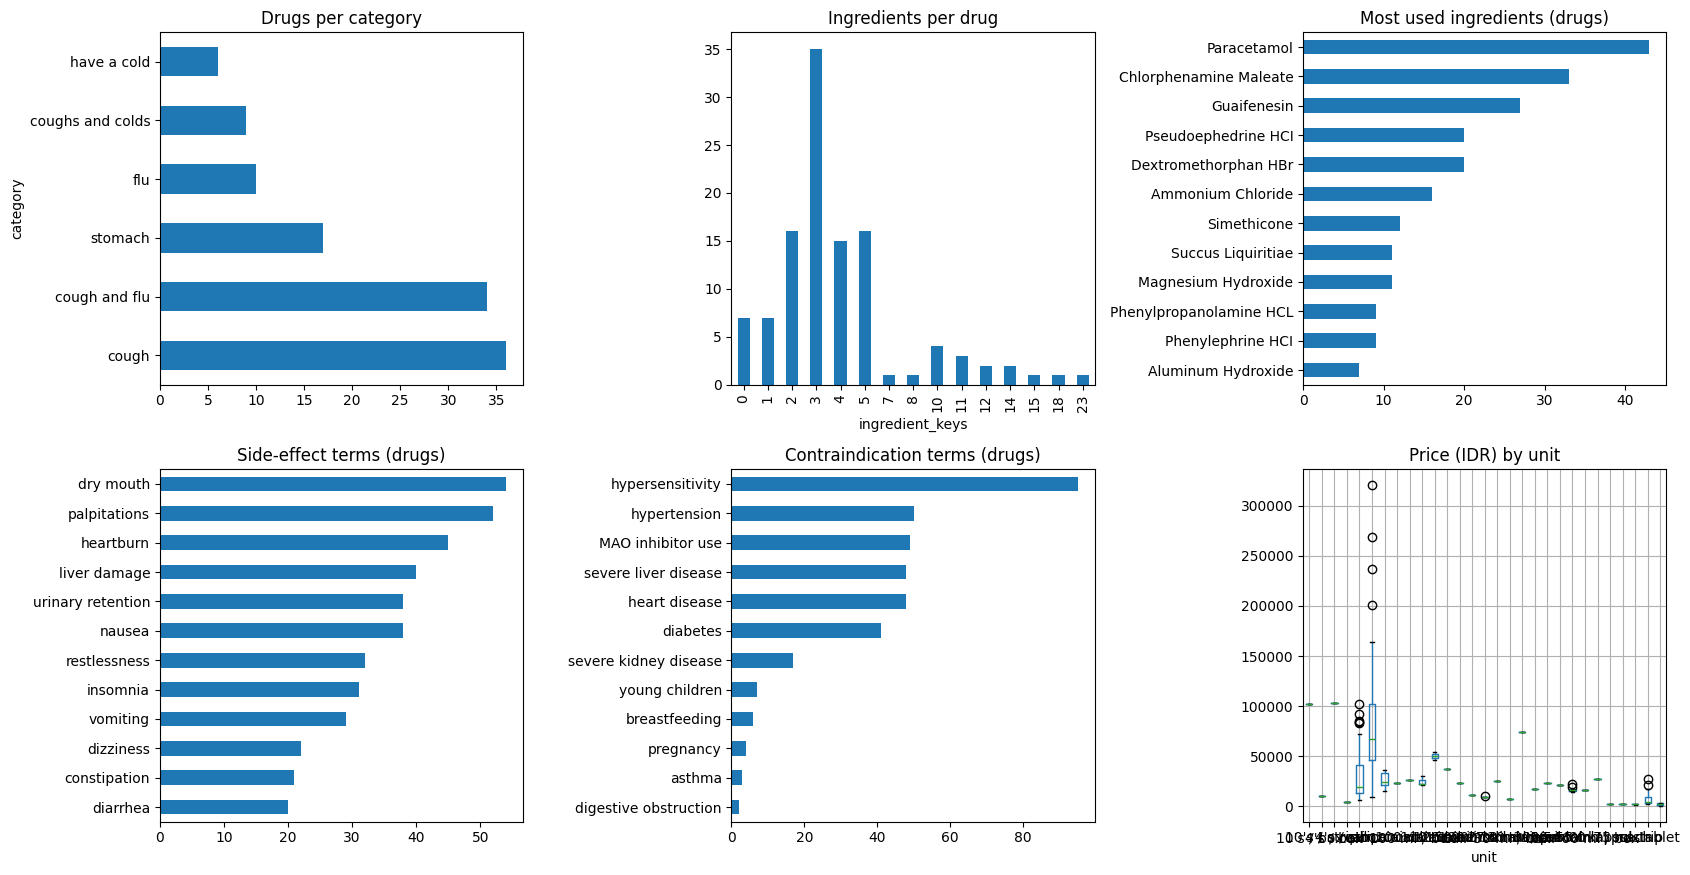

drugs: 112 | with >=1 ingredient: 105 | with >=1 side-effect statement: 110 | with a price: 110
Ingredients shared by >= 2 drugs: 64 of 185 | drugs with interaction statements: 102 | drugs with >= 1 extracted side-effect term: 100


In [9]:
# ---- exploratory analysis that informs the graph design -----------------------------------------------------------------------
rd = pd.DataFrame(recs)
def bar(series, ax, title, horizontal=True, n=None):
    s = series.sort_values().tail(n) if n else series
    if len(s) == 0 or s.sum() == 0:
        ax.text(0.5, 0.5, "no data - check the extraction above", ha="center", va="center"); ax.set_title(title + "  (EMPTY)"); ax.axis("off"); return
    (s.plot.barh if horizontal else s.plot.bar)(ax=ax, title=title)
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
bar(rd.category.value_counts(), axs[0, 0], "Drugs per category")
bar(rd.ingredient_keys.map(len).value_counts().sort_index(), axs[0, 1], "Ingredients per drug", horizontal=False)
bar(pd.Series(Counter(n for ns in rd.ingredient_names for n in ns), dtype=float), axs[0, 2], "Most used ingredients (drugs)", n=12)
bar(pd.Series(Counter(t for ts in rd.effect_terms for t in ts), dtype=float), axs[1, 0], "Side-effect terms (drugs)", n=12)
bar(pd.Series(Counter(t for ts in rd.contra_terms for t in ts), dtype=float), axs[1, 1], "Contraindication terms (drugs)", n=12)
if len(tables["price"]): tables["price"].boxplot(column="price", by="unit", ax=axs[1, 2]); axs[1, 2].set_title("Price (IDR) by unit"); plt.suptitle("")
else: axs[1, 2].text(0.5, 0.5, "no prices parsed", ha="center"); axs[1, 2].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/eda.png", dpi=130); plt.show()
print("drugs:", len(rd), "| with >=1 ingredient:", int((rd.ingredient_keys.map(len) > 0).sum()), "| with >=1 side-effect statement:", int((rd.side_effects.map(len) > 0).sum()),
      "| with a price:", int((rd.prices.map(len) > 0).sum()))
shared = Counter(k for ks in rd.ingredient_keys for k in ks)
print("Ingredients shared by >= 2 drugs:", sum(1 for v in shared.values() if v >= 2), "of", len(shared),
      "| drugs with interaction statements:", int((rd.interactions.map(len) > 0).sum()),
      "| drugs with >= 1 extracted side-effect term:", int((rd.effect_terms.map(len) > 0).sum()))

**What the EDA tells us for the design.**
1. **Shared ingredients** connect drugs (`Drug → Ingredient ← Drug`) — the basis for multi-hop questions.
2. **Free text** (side effects, contraindications, interactions) is where most of the information sits. A table copy would store it as strings; extracting **terms** (e.g. *drowsiness*, *pregnancy*)
   turns it into shared nodes: *"which drugs in category X cause drowsiness?"* becomes a 2-hop traversal and *"how many drugs list headache?"* becomes a count.
3. **Interaction sentences** mention other ingredients — linking them gives an `INVOLVES` edge from the sentence to the ingredient.
4. **Prices per unit** (strip, box, bottle...) are numeric and support ranking questions.
Extraction is **rule-based and validated** (coverage report above + hand-label sheets below); every extracted link keeps its source sentence (`evidence`) for provenance.

## Task 2 — Graph model design (Neo4j Aura)

**Node labels**

| Label | Key | Other properties | Why it exists |
|---|---|---|---|
| `Drug` | `id` (unique) | `name`, `name_key`, `category`, `indication`, `dose_adult`, `dose_children`, `usage_period`, `usage_rules[]`, `side_effects[]`, `contraindications[]`, `interactions[]`, `text`, `src_id`, `source_file` | One OTC product; keeps the **raw statements** (provenance, grounded answers) |
| `Category` | `key` | `name` | Disease category (stomach, cough, flu …); groups drugs |
| `Ingredient` | `key` | `name` | Active compound; hub linking drugs that share it |
| `SideEffectTerm` | `key` | `name` | Concept extracted from side-effect sentences (rule-based vocabulary) |
| `ContraTerm` | `key` | `name` | Condition extracted from contraindication sentences |
| `Interaction` | `id` (unique) | `text` | One interaction sentence (kept as a node so it can link to ingredients) |
| `Unit` | `key` | `name` | Price unit (strip, box, bottle …) |

**Relationship types**

| Type | Direction | Properties | Cardinality | Why it exists |
|---|---|---|---|---|
| `IN_CATEGORY` | `(Drug)→(Category)` | – | N:1 | Category questions and filters |
| `CONTAINS` | `(Drug)→(Ingredient)` | `amount`, `unit` | N:M | Composition; the multi-hop hub |
| `MAY_CAUSE` | `(Drug)→(SideEffectTerm)` | `evidence`, `line_no` | N:M | **Extracted** from free text; evidence = source sentence |
| `CONTRAINDICATED_IN` | `(Drug)→(ContraTerm)` | `evidence`, `line_no` | N:M | **Extracted** from free text |
| `HAS_INTERACTION` | `(Drug)→(Interaction)` | – | 1:N | Keeps each statement addressable |
| `INVOLVES` | `(Interaction)→(Ingredient)` | – | N:M | **Extracted**: ingredient named in the sentence |
| `SOLD_AS` | `(Drug)→(Unit)` | `price` (IDR) | N:M | Numeric price per unit |
| `SHARES_INGREDIENT` *(derived)* | `(Drug)–(Drug)` | `n` | N:M | Pre-computed similarity / alternatives |

Indexes: uniqueness constraints on all keys; **full-text** indexes on drug name, ingredient name and drug text; b-tree on `Drug.name_key`.

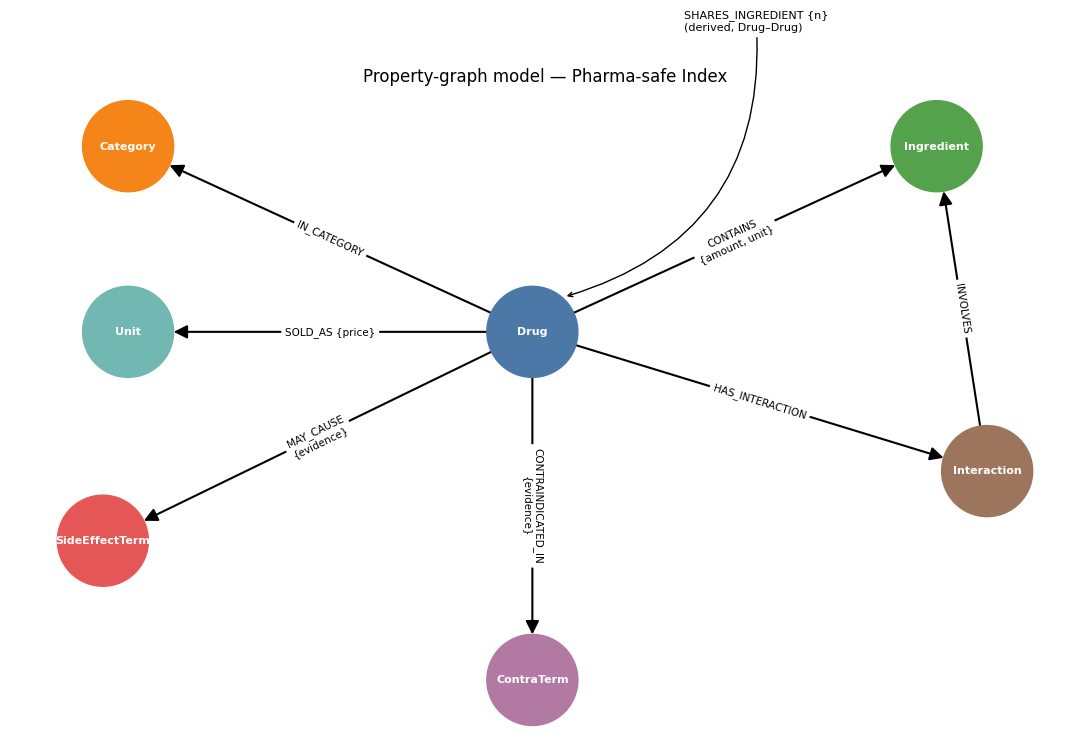

In [10]:
# ---- schema diagram -----------------------------------------------------------------------------------------------------------
import networkx as nx
G = nx.DiGraph()
pos = {"Drug": (0, 0), "Category": (-3.2, 1.6), "Ingredient": (3.2, 1.6), "SideEffectTerm": (-3.4, -1.8), "ContraTerm": (0, -3.0),
       "Interaction": (3.6, -1.2), "Unit": (-3.2, 0.0)}
edges = [("Drug", "Category", "IN_CATEGORY"), ("Drug", "Ingredient", "CONTAINS\n{amount, unit}"), ("Drug", "SideEffectTerm", "MAY_CAUSE\n{evidence}"),
         ("Drug", "ContraTerm", "CONTRAINDICATED_IN\n{evidence}"), ("Drug", "Interaction", "HAS_INTERACTION"),
         ("Interaction", "Ingredient", "INVOLVES"), ("Drug", "Unit", "SOLD_AS {price}")]
for a, b, l in edges: G.add_edge(a, b, label=l)
colors = {"Drug": "#4C78A8", "Category": "#F58518", "Ingredient": "#54A24B", "SideEffectTerm": "#E45756", "ContraTerm": "#B279A2", "Interaction": "#9D755D", "Unit": "#72B7B2"}
fig, ax = plt.subplots(figsize=(11, 7.5))
nx.draw_networkx_nodes(G, pos, node_size=4300, node_color=[colors[n] for n in G.nodes], ax=ax)
nx.draw_networkx_labels(G, pos, font_color="white", font_weight="bold", font_size=8, ax=ax)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=4300, width=1.5, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7.5, ax=ax)
ax.annotate("SHARES_INGREDIENT {n}\n(derived, Drug–Drug)", xy=(0.25, 0.3), xytext=(1.2, 2.6), fontsize=8, arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.4"))
ax.set_title("Property-graph model — Pharma-safe Index"); ax.axis("off"); plt.tight_layout()
plt.savefig(f"{OUT}/figures/graph_schema.png", dpi=140); plt.show()

In [11]:
# ---- connect to Neo4j Aura (credentials from Kaggle Secrets only) ------------------------------------------------------------------
from neo4j import GraphDatabase
try:
    from kaggle_secrets import UserSecretsClient
    _sec = UserSecretsClient(); get_secret = lambda k: _sec.get_secret(k)
except Exception:
    get_secret = lambda k: os.environ[k]
driver = GraphDatabase.driver(get_secret("NEO4J_URI"), auth=(get_secret("NEO4J_USERNAME"), get_secret("NEO4J_PASSWORD")))
driver.verify_connectivity(); print("Connected to Neo4j Aura.")
try:                                                                  # show which database will be used
    with driver.session(database=NEO4J_DB) as _s:
        print("database in use:", _s.run("CALL db.info() YIELD name RETURN name").single()["name"])
except Exception as _e:
    print("(could not read the database name:", str(_e)[:100], ")")

def q(cypher, **params):
    with driver.session(database=NEO4J_DB) as s:
        return pd.DataFrame(s.execute_read(lambda tx: tx.run(cypher, **params).data()))
def run_write(cypher, **params):
    with driver.session(database=NEO4J_DB) as s:
        return s.execute_write(lambda tx: tx.run(cypher, **params).consume())
def write_batches(cypher, rows, batch=500):
    """Parameterised, batched UNWIND ... MERGE."""
    with driver.session(database=NEO4J_DB) as s:
        for i in range(0, len(rows), batch):
            chunk = rows[i:i + batch]
            s.execute_write(lambda tx, c=chunk: tx.run(cypher, rows=c).consume())

Connected to Neo4j Aura.
database in use: 9b854063


In [12]:
# ---- wipe (optional), constraints and indexes ---------------------------------------------------------------------------------------
if WIPE_GRAPH:
    with driver.session(database=NEO4J_DB) as s:
        s.run("MATCH (n) CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 5000 ROWS").consume()
    print("Existing graph deleted.")
DDL = [
 "CREATE CONSTRAINT drug_id IF NOT EXISTS FOR (d:Drug) REQUIRE d.id IS UNIQUE",
 "CREATE CONSTRAINT category_key IF NOT EXISTS FOR (c:Category) REQUIRE c.key IS UNIQUE",
 "CREATE CONSTRAINT ingredient_key IF NOT EXISTS FOR (i:Ingredient) REQUIRE i.key IS UNIQUE",
 "CREATE CONSTRAINT effect_key IF NOT EXISTS FOR (t:SideEffectTerm) REQUIRE t.key IS UNIQUE",
 "CREATE CONSTRAINT contra_key IF NOT EXISTS FOR (t:ContraTerm) REQUIRE t.key IS UNIQUE",
 "CREATE CONSTRAINT interaction_id IF NOT EXISTS FOR (x:Interaction) REQUIRE x.id IS UNIQUE",
 "CREATE CONSTRAINT unit_key IF NOT EXISTS FOR (u:Unit) REQUIRE u.key IS UNIQUE",
 "CREATE INDEX drug_name_key IF NOT EXISTS FOR (d:Drug) ON (d.name_key)",
 "CREATE FULLTEXT INDEX drug_name_ft IF NOT EXISTS FOR (d:Drug) ON EACH [d.name]",
 "CREATE FULLTEXT INDEX ingredient_name_ft IF NOT EXISTS FOR (i:Ingredient) ON EACH [i.name]",
 "CREATE FULLTEXT INDEX drug_text_ft IF NOT EXISTS FOR (d:Drug) ON EACH [d.text]",
]
for stmt in DDL: run_write(stmt)
display(q("SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties RETURN name, labelsOrTypes, properties"))
display(q("SHOW INDEXES YIELD name, type, labelsOrTypes, properties WHERE type <> 'LOOKUP' RETURN name, type, labelsOrTypes, properties"))

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=1, column=11, offset=10>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 10, 'line': 1, 'column': 11}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 5000 ROWS'


Existing graph deleted.


,name,labelsOrTypes,properties
0,category_key,[Category],[key]
1,code_Course_key,[Course],[code]
2,code_Department_key,[Department],[code]
3,contra_key,[ContraTerm],[key]
4,drug_id,[Drug],[id]
5,effect_key,[SideEffectTerm],[key]
6,id_Professor_key,[Professor],[id]
7,id_Student_key,[Student],[id]
8,ingredient_key,[Ingredient],[key]
9,interaction_id,[Interaction],[id]


,name,type,labelsOrTypes,properties
0,category_key,RANGE,[Category],[key]
1,code_Course_key,RANGE,[Course],[code]
2,code_Department_key,RANGE,[Department],[code]
3,contra_key,RANGE,[ContraTerm],[key]
4,drug_id,RANGE,[Drug],[id]
5,drug_name_ft,FULLTEXT,[Drug],[name]
6,drug_name_key,RANGE,[Drug],[name_key]
7,drug_text_ft,FULLTEXT,[Drug],[text]
8,effect_key,RANGE,[SideEffectTerm],[key]
9,id_Professor_key,RANGE,[Professor],[id]


In [13]:
# ---- load the graph: parameterised, batched UNWIND ... MERGE ------------------------------------------------------------------------------
import rag_common as rc
t0 = time.perf_counter()
SRC = "Pharma-safe Index Dataset (Mendeley, 10.17632/m78j7ctwhn.2)"
drug_rows = [dict(id=r["id"], src_id=r["src_id"], name=r["name"], name_key=r["name_key"], category=r["category"], indication=r["indication"],
                  dose_adult=r["dose_adult"], dose_children=r["dose_children"], dose_other=r["dose_other"], usage_period=r["usage_period"],
                  usage_rules=r["usage_rules"], side_effects=r["side_effects"], contraindications=r["contraindications"],
                  interactions=r["interactions"], text=rc.serialize_drug(r), source_file=SRC) for r in recs]
write_batches("""UNWIND $rows AS r MERGE (d:Drug {id:r.id})
  SET d.src_id=r.src_id, d.name=r.name, d.name_key=r.name_key, d.category=r.category, d.indication=r.indication,
      d.dose_adult=r.dose_adult, d.dose_children=r.dose_children, d.dose_other=r.dose_other, d.usage_period=r.usage_period,
      d.usage_rules=r.usage_rules, d.side_effects=r.side_effects, d.contraindications=r.contraindications,
      d.interactions=r.interactions, d.text=r.text, d.source_file=r.source_file""", drug_rows)

cats = {r["category_key"]: r["category"] for r in recs}
ings = {k: n for r in recs for k, n in zip(r["ingredient_keys"], r["ingredient_names"])}
units = {u: u for u in tables["price"]["unit_key"].unique()}
write_batches("UNWIND $rows AS r MERGE (c:Category {key:r.key}) SET c.name=r.name", [dict(key=k, name=n) for k, n in cats.items()])
write_batches("UNWIND $rows AS r MERGE (i:Ingredient {key:r.key}) SET i.name=r.name", [dict(key=k, name=n) for k, n in ings.items()])
write_batches("UNWIND $rows AS r MERGE (t:SideEffectTerm {key:r.key}) SET t.name=r.key", [dict(key=k) for k in tables["effect_links"].term.unique()])
write_batches("UNWIND $rows AS r MERGE (t:ContraTerm {key:r.key}) SET t.name=r.key", [dict(key=k) for k in tables["contra_links"].term.unique()])
write_batches("UNWIND $rows AS r MERGE (u:Unit {key:r.key}) SET u.name=r.key", [dict(key=k) for k in units])
write_batches("UNWIND $rows AS r MERGE (x:Interaction {id:r.id}) SET x.text=r.text", [dict(id=int(a), text=b) for a, b in zip(tables["interactions"].inter_id, tables["interactions"].text)])

write_batches("UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (c:Category {key:r.ckey}) MERGE (d)-[:IN_CATEGORY]->(c)",
              [dict(id=r["id"], ckey=r["category_key"]) for r in recs])
write_batches("""UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (i:Ingredient {key:r.ikey})
                 MERGE (d)-[c:CONTAINS]->(i) SET c.amount=r.amount, c.unit=r.unit""",
              [dict(id=int(x.drug_id), ikey=x.key, amount=x.amount, unit=x.unit) for x in tables["composition"].itertuples()])
write_batches("""UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (t:SideEffectTerm {key:r.k})
                 MERGE (d)-[m:MAY_CAUSE]->(t) SET m.evidence=r.ev, m.line_no=r.ln""",
              [dict(id=int(x.drug_id), k=x.term, ev=x.evidence, ln=int(x.line_no)) for x in tables["effect_links"].itertuples()])
write_batches("""UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (t:ContraTerm {key:r.k})
                 MERGE (d)-[m:CONTRAINDICATED_IN]->(t) SET m.evidence=r.ev, m.line_no=r.ln""",
              [dict(id=int(x.drug_id), k=x.term, ev=x.evidence, ln=int(x.line_no)) for x in tables["contra_links"].itertuples()])
write_batches("UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (x:Interaction {id:r.iid}) MERGE (d)-[:HAS_INTERACTION]->(x)",
              [dict(id=int(a), iid=int(b)) for a, b in zip(tables["interactions"].drug_id, tables["interactions"].inter_id)])
write_batches("UNWIND $rows AS r MATCH (x:Interaction {id:r.iid}) MATCH (i:Ingredient {key:r.k}) MERGE (x)-[:INVOLVES]->(i)",
              [dict(iid=int(a), k=b) for a, b in zip(tables["interaction_links"].inter_id, tables["interaction_links"].ingredient_key)])
write_batches("UNWIND $rows AS r MATCH (d:Drug {id:r.id}) MATCH (u:Unit {key:r.u}) MERGE (d)-[s:SOLD_AS {price:r.p}]->(u)",
              [dict(id=int(x.drug_id), u=x.unit_key, p=int(x.price)) for x in tables["price"].itertuples()])
run_write("""MATCH (a:Drug)-[:CONTAINS]->(i:Ingredient)<-[:CONTAINS]-(b:Drug) WHERE a.id < b.id
             WITH a, b, count(DISTINCT i) AS n MERGE (a)-[r:SHARES_INGREDIENT]->(b) SET r.n = n""")
BUILD["graph_load_s"] = round(time.perf_counter() - t0, 2)
print("Graph loaded in", BUILD["graph_load_s"], "s")

Graph loaded in 9.96 s


In [14]:
# ---- validation: (1) counts vs source tables, (2) record-level audit with provenance, (3) hand-label sheets for the extraction --------------
expected = {"Drug": len(recs), "Category": len(cats), "Ingredient": len(ings), "SideEffectTerm": tables["effect_links"].term.nunique(),
            "ContraTerm": tables["contra_links"].term.nunique(), "Unit": len(units), "Interaction": len(tables["interactions"]),
            "IN_CATEGORY": len(recs), "CONTAINS": len(tables["composition"]), "MAY_CAUSE": len(tables["effect_links"]),
            "CONTRAINDICATED_IN": len(tables["contra_links"]), "HAS_INTERACTION": len(tables["interactions"]),
            "INVOLVES": len(tables["interaction_links"]),
            "SOLD_AS": len(tables["price"].drop_duplicates(["drug_id", "unit_key", "price"]))}
node_counts = q("MATCH (n) RETURN labels(n)[0] AS k, count(*) AS n").set_index("k").n.to_dict()
rel_counts  = q("MATCH ()-[r]->() RETURN type(r) AS k, count(*) AS n").set_index("k").n.to_dict()
got = {**node_counts, **rel_counts}
val = pd.DataFrame({"expected (pandas)": expected, "in graph (Cypher)": {k: got.get(k, 0) for k in expected}})
val["match"] = val["expected (pandas)"] == val["in graph (Cypher)"]
display(val); assert val["match"].all(), "Graph counts differ from the cleaned tables!"
print("Derived SHARES_INGREDIENT:", got.get("SHARES_INGREDIENT"))

# record-level audit against the ORIGINAL raw tables (through src_id)
samp = recs if len(recs) <= 30 else [recs[i] for i in np.random.default_rng(SEED).choice(len(recs), 30, replace=False)]
g = q("""MATCH (d:Drug) WHERE d.id IN $ids
         OPTIONAL MATCH (d)-[:CONTAINS]->(i:Ingredient) WITH d, collect(i.key) AS ikeys
         OPTIONAL MATCH (d)-[s:SOLD_AS]->(u:Unit) WITH d, ikeys, collect(u.key + ':' + toString(s.price)) AS prices
         RETURN d.id AS id, d.src_id AS src_id, d.name_key AS name_key, d.category AS category, ikeys, prices""", ids=[r["id"] for r in samp]).set_index("id")
audit = []
for rid, row in g.iterrows():
    d_raw = T_raw["drug"][T_raw["drug"].id == row.src_id].iloc[0]
    comp_raw = {key_of(x) for x in T_raw["comp"][T_raw["comp"].drug_id == row.src_id]["name"]}
    pr_raw = {f"{key_of(u.lower())}:{parse_price(p)}" for u, p in zip(T_raw["price"][T_raw["price"].drug_id == row.src_id]["unit"], T_raw["price"][T_raw["price"].drug_id == row.src_id]["price"])}
    audit.append(dict(id=rid, name=key_of(d_raw["name"]) == row["name_key"], category=key_of(d_raw["category"]) == key_of(row["category"]),
                      ingredients=comp_raw == set(row["ikeys"]), prices=pr_raw == set(row["prices"])))
audit = pd.DataFrame(audit); audit.to_csv(f"{OUT}/extraction_validation.csv", index=False)
print("\nRecord-level agreement with the raw tables (n =", len(audit), "):\n", audit[["name", "category", "ingredients", "prices"]].mean().round(3).to_string())

# hand-label sheets for the TEXT extraction (fill 'hand_terms' with the terms YOU would assign, then report precision/recall in the paper)
def sheet(links, kind, n=40):
    s = links.sample(min(n, len(links)), random_state=SEED)[["drug_id", "term", "evidence"]].copy()
    s["kind"], s["hand_ok"] = kind, ""
    return s
pd.concat([sheet(tables["effect_links"], "side effect"), sheet(tables["contra_links"], "contraindication")]).to_csv(f"{OUT}/extraction_handcheck_terms.csv", index=False)
print("\nWrote extraction_handcheck_terms.csv (fill hand_ok = 1/0 for each extracted term; precision = mean(hand_ok)).")

,expected (pandas),in graph (Cypher),match
Drug,112,112,True
Category,6,6,True
Ingredient,185,185,True
SideEffectTerm,25,25,True
ContraTerm,15,15,True
Unit,29,29,True
Interaction,169,169,True
IN_CATEGORY,112,112,True
CONTAINS,480,480,True
MAY_CAUSE,511,511,True


Derived SHARES_INGREDIENT: 1659

Record-level agreement with the raw tables (n = 30 ):
 name           1.0
category       1.0
ingredients    1.0
prices         1.0

Wrote extraction_handcheck_terms.csv (fill hand_ok = 1/0 for each extracted term; precision = mean(hand_ok)).


In [15]:
# ---- exploratory Cypher queries (outputs for the report) ------------------------------------------------------------------------------------
print("Q1  Node and relationship counts"); display(pd.concat([pd.Series(node_counts, name="nodes"), pd.Series(rel_counts, name="relationships")], axis=1))
print("Q2  Drugs per category")
display(q("MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) RETURN c.name AS category, count(d) AS drugs ORDER BY drugs DESC"))
print("Q3  Most shared ingredients (drugs containing them)")
display(q("MATCH (i:Ingredient)<-[:CONTAINS]-(d:Drug) RETURN i.name AS ingredient, count(DISTINCT d) AS drugs ORDER BY drugs DESC LIMIT 10"))
print("Q4  Multi-hop: drugs in the largest category that list the most common side effect")
display(q("""MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) WITH c, count(d) AS n ORDER BY n DESC LIMIT 1
             MATCH (t:SideEffectTerm)<-[:MAY_CAUSE]-(x:Drug) WITH c, t, count(x) AS m ORDER BY m DESC LIMIT 1
             MATCH (c)<-[:IN_CATEGORY]-(d:Drug)-[r:MAY_CAUSE]->(t)
             RETURN c.name AS category, t.name AS side_effect, d.name AS drug, left(r.evidence, 90) AS source_sentence LIMIT 10"""))
print("Q5  Drug pairs sharing the most ingredients")
display(q("MATCH (a:Drug)-[r:SHARES_INGREDIENT]->(b:Drug) RETURN a.name AS drug_a, b.name AS drug_b, r.n AS shared ORDER BY shared DESC, drug_a LIMIT 10"))
print("Q6  Interaction sentences that mention an ingredient (text → ingredient link)")
display(q("""MATCH (d:Drug)-[:HAS_INTERACTION]->(x:Interaction)-[:INVOLVES]->(i:Ingredient)
             RETURN d.name AS drug, i.name AS mentions, left(x.text, 100) AS sentence LIMIT 8"""))
print("Q7  Full-text index lookup (fuzzy)")
display(q("CALL db.index.fulltext.queryNodes('drug_name_ft', $s) YIELD node, score RETURN node.name AS drug, round(score, 2) AS score LIMIT 5", s=recs[0]["name"].split()[0] + "~"))

Q1  Node and relationship counts


,nodes,relationships
Drug,112.0,NaN
Category,6.0,NaN
Ingredient,185.0,NaN
SideEffectTerm,25.0,NaN
ContraTerm,15.0,NaN
Unit,29.0,NaN
Interaction,169.0,NaN
IN_CATEGORY,NaN,112.0
CONTAINS,NaN,480.0
MAY_CAUSE,NaN,511.0


Q2  Drugs per category


,category,drugs
0,cough,36
1,cough and flu,34
2,stomach,17
3,flu,10
4,coughs and colds,9
5,have a cold,6


Q3  Most shared ingredients (drugs containing them)


,ingredient,drugs
0,Paracetamol,43
1,Chlorphenamine Maleate,33
2,Guaifenesin,27
3,Dextromethorphan HBr,20
4,Pseudoephedrine HCI,20
5,Ammonium Chloride,16
6,Simethicone,12
7,Succus Liquiritiae,11
8,Magnesium Hydroxide,11
9,Phenylpropanolamine HCL,9


... (5 outputs left out)

,drug,mentions,sentence
0,Antasida Doen Tablet Kunyah,Aluminum Hydroxide,Aluminum hydroxide will reduce the absorption ...
1,New Enzyplex Tablet,Vitamin b6,Consuming vitamin B6 above 5-10 mg per day can...
2,Decadryl,Diphenhydramine HCI,Diphenhydramine HCI reduces the effects of ora...
3,Decadryl,Alcohol,Diphenhydramine HCl produces dangerous effects...
4,Decadryl,Diphenhydramine Hydrochloride,Diphenhydramine HCl produces dangerous effects...
5,Decadryl,Diphenhydramine HCI,Diphenhydramine HCI and Phenobarbital are both...
6,Decadryl,Diphenhydramine Hydrochloride,Diphenhydramine HCl increases the cardiovascul...
7,Decadryl,Ammonium Chloride,"Ammonium chloride lowers the pH of urine, ther..."


Q7  Full-text index lookup (fuzzy)


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL db.index.fulltext.queryNodes('drug_name_ft', $s) YIELD node, score RETURN node.name AS drug, round(score, 2) AS score LIMIT 5"


,drug,score
0,Antasida Doen Tablet Kunyah,1.57


## Task 3 — GraphRAG pipeline
**Design (code in `graph_rag.py`):**
1. **Entity linking** — drug names and ingredients: *exact* (longest span first) → unambiguous *alias* → *fuzzy* (RapidFuzz ≥ 90, typos). Categories are linked when quoted or next to the word "category"
   (so a category called "diarrhea" is not confused with the side effect). **Side-effect / contraindication terms** are linked through the *same vocabulary* used for extraction; cue words
   ("contraindicated", "side effect") decide which kind is meant.
2. **Planning** — rule-based intent detection selects one or more of ~30 **parameterised, read-only Cypher templates**: single-drug "cards" (price, ingredients, dose, side effects …), 2-3-hop traversals
   (shared ingredients, category + side effect, interaction + ingredient), counts, rankings and intersections.
3. **Evidence** — each result row becomes a numbered fact `G1, G2, …` that quotes the **source sentence** when it came from extracted text, with provenance (`row_ids` = drug ids).
4. **Generation** — shared generator + prompt (`rag_common.py`): answer only from evidence, cite ids, **decline** when the evidence cannot answer (`answerable=false`).
5. **Optional Text2Cypher** — an LLM writes Cypher; it is validated (single statement, read-clause whitelist, forbidden-keyword scan, `EXPLAIN`, `LIMIT` enforced) and run in a read transaction.
   A *hybrid* mode falls back to it when no template applies.

In [16]:
# ---- start Ollama and pull the generator -----------------------------------------------------------------------------------------------------
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null 2>&1
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
import rag_common as rc
rc.ensure_ollama()
t0 = time.perf_counter(); rc.pull(GEN_MODEL); print("model ready in", round(time.perf_counter() - t0, 1), "s")
open(f"{OUT}/schema_note.txt", "w").write(rc.SCHEMA_NOTE); print(rc.SCHEMA_NOTE)

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest 
pulling 2bada8a74506:   0% ▕                  ▏ 365 KB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  34 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   2% ▕                  ▏ 106 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   4% ▕                  ▏ 203 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   5% ▕                  ▏ 238 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   7% ▕█                 ▏ 312 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   9% ▕█          

model ready in 39.9 s
The database covers 112 over-the-counter drugs sold in pharmacies in Yogyakarta, Indonesia. For each drug it holds only: name, disease category, indication, composition (ingredients with amounts), side effects, contraindications, drug interactions, dose (adult / children), usage rules, period of use and price per unit. It does NOT hold manufacturers, mechanisms of action, storage or shelf life, regulatory approval, clinical evidence, prescription-only drugs, or any drug that is not one of these products.


pulling manifest 
pulling 2bada8a74506: 100% ▕█████████████████ ▏ 4.7 GB/4.7 GB  200 MB/s      0s
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 2f15b3218f05: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest ⠙ pulling manifest 
pulling 2bada8a74506: 100% ▕█████████████████ ▏ 4.7 GB/4.7 GB  200 MB/s      0s
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 2f15b3218f05: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest ⠹ pulling manifest 
pulling 2bada8a74506: 100% ▕█████████████████ ▏ 4.7 GB/4.7 GB  200 MB/s      0s
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 2f15b3218f05: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest 
writing manifest 
success 


In [17]:
# ---- initialise the retriever -------------------------------------------------------------------------------------------------------------------
import importlib, graph_rag as gr
importlib.reload(gr)
idx = gr.EntityIndex(driver, NEO4J_DB)
t0 = time.perf_counter(); print("entity index sizes:", idx.load()); BUILD["entity_index_s"] = round(time.perf_counter() - t0, 2)
R = gr.GraphRetriever(driver, NEO4J_DB, idx)

def ask(question, mode="template", model=GEN_MODEL, show=True):
    ret = R.retrieve(question, k=10, mode=mode, model=model)
    ans = rc.generate_answer(model, question, ret["items"])
    if show:
        print("Q:", question)
        print("   links  :", [(l["type"], l["name"], l["method"]) for l in ret.get("links", [])])
        print("   intents:", ret.get("intents"), "| mode:", ret["mode"], "| records:", ret.get("n_records"))
        for it in ret["items"][:6]: print(f"   [{it['id']}] {it['text'][:170]}")
        if len(ret["items"]) > 6: print(f"   ... {len(ret['items']) - 6} more facts")
        print(f"   ANSWER ({'answerable' if ans['answerable'] else 'DECLINED'}): {ans['answer']}   cites={ans['citations']}")
        print(f"   retrieval {ret['retrieval_latency_s']*1000:.0f} ms | generation {ans['gen_latency_s']:.1f} s | prompt tokens {ans['prompt_tokens']}\n")
    return ret, ans

entity index sizes: {'drug': 107, 'ingredient': 185, 'category': 6, 'unit': 29}


In [18]:
# ---- demo: single-hop, multi-hop, aggregation, descriptive and unanswerable questions ----------------------------------------------------
r0 = next(r for r in recs if r["effect_terms"] and r["contra_terms"] and len(r["ingredient_names"]) >= 1)
top_cat = Counter(r["category"] for r in recs).most_common(1)[0][0]
top_eff = Counter(t for r in recs for t in r["effect_terms"]).most_common(1)[0][0]
top_ing = Counter(n for r in recs for n in r["ingredient_names"]).most_common(1)[0][0]
demo = [f"Which disease category does '{r0['name']}' belong to?",
        f"Which active ingredients does '{r0['name']}' contain?",
        f"Which other drugs share at least one active ingredient with '{r0['name']}'?",
        f"Which drugs in the '{top_cat}' category list {top_eff} as a side effect?",
        f"How many drugs contain {top_ing}?",
        "Which 3 categories have the most drugs?",
        f"What precautions apply to '{r0['name']}'?",
        f"Describe the drug '{r0['name']}': what is it used for and what does it contain?",
        f"Who manufactures '{r0['name']}'?",                 # not in the data -> must decline
        "What is the price of the drug 'Zorvexa Plus 9' per strip?"]   # entity not in the data -> must decline
for qn in demo: ask(qn)

Q: Which disease category does 'Antasida Doen Tablet Kunyah' belong to?
   links  : [('drug', 'Antasida Doen Tablet Kunyah', 'exact')]
   intents: ['drug_card'] | mode: template | records: 1
   [G1] Drug 'Antasida Doen Tablet Kunyah' belongs to the disease category 'stomach'.
   ANSWER (answerable): stomach   cites=['G1']
   retrieval 581 ms | generation 118.2 s | prompt tokens 330

Q: Which active ingredients does 'Antasida Doen Tablet Kunyah' contain?
   links  : [('drug', 'Antasida Doen Tablet Kunyah', 'exact')]
   intents: ['drug_card'] | mode: template | records: 1
   [G1] 'Antasida Doen Tablet Kunyah' contains: Aluminum Hydroxide 200 mg, Magnesium Hydroxide 200 mg.
   ANSWER (answerable): Aluminum Hydroxide 200 mg, Magnesium Hydroxide 200 mg.   cites=['G1']
   retrieval 1359 ms | generation 1.1 s | prompt tokens 341

Q: Which other drugs share at least one active ingredient with 'Antasida Doen Tablet Kunyah'?
   links  : [('drug', 'Antasida Doen Tablet Kunyah', 'exact')]
   inten

In [19]:
# ---- Text2Cypher: generated Cypher is validated and read-only --------------------------------------------------------------------------------
for qn in [f"How many drugs contain {top_ing}?", f"Which drugs list {top_eff} as a side effect?", "Which 3 categories have the most drugs?"]:
    r = R.retrieve(qn, mode="text2cypher", model=GEN_MODEL)
    print("Q:", qn, "\n   cypher :", r["cypher"][0], "\n   status :", r["status"], "| rows:", r["n_records"], "\n   first  :", r["items"][0]["text"] if r["items"] else None, "\n")
print("Safety checks (all must be rejected):")
for bad in ["MATCH (n) DETACH DELETE n", "CREATE (x:Hack) RETURN x", "MATCH (n) SET n.name='x' RETURN n", "CALL apoc.cypher.runMany('x',{})",
            "MATCH (n) RETURN n; MATCH (m) RETURN m", "LOAD CSV FROM 'http://x' AS r RETURN r"]:
    print("  ", gr.GraphRetriever.validate_cypher(bad)[1], "<-", bad)

Q: How many drugs contain Paracetamol? 
   cypher : MATCH (:Ingredient {key:'paracetamol'})<-[:CONTAINS]-(d:Drug) RETURN count(DISTINCT d) AS n LIMIT 50 
   status : ok | rows: 1 
   first  : Result row: n=43 

Q: Which drugs list dry mouth as a side effect? 
   cypher : MATCH (:SideEffectTerm {key:'dry mouth'})<-[:MAY_CAUSE]-(d:Drug) RETURN DISTINCT d.name AS name ORDER BY name LIMIT 50 
   status : ok | rows: 50 
   first  : Result row: name=Alpara 

Q: Which 3 categories have the most drugs? 
   cypher : MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) RETURN c.name AS name, count(d) AS n ORDER BY n DESC LIMIT 3 
   status : ok | rows: 3 
   first  : Result row: name=cough; n=36 

Safety checks (all must be rejected):
   forbidden keyword: DETACH <- MATCH (n) DETACH DELETE n
   must start with MATCH/WITH/UNWIND <- CREATE (x:Hack) RETURN x
   forbidden keyword: SET <- MATCH (n) SET n.name='x' RETURN n
   must start with MATCH/WITH/UNWIND <- CALL apoc.cypher.runMany('x',{})
   multiple sta

In [20]:
# ---- entity-linking spot check: typos, aliases, category-vs-term, cue words -------------------------------------------------------------------
tests = [r0["name"], r0["name"].lower(), r0["name"][:-2], " ".join(r0["name"].split()[:2]), top_ing.upper(),
         f"drugs that cause {top_eff}", f"drugs contraindicated in {sorted(r0['contra_terms'])[0]}",
         f"how many drugs belong to the {top_cat} category"]
rows = []
for v in tests:
    links = R.resolve(v, idx.link(v)); rows.append({"input": v, "linked": [(l["type"], l["name"], l["method"]) for l in links]})
pd.DataFrame(rows)

,input,linked
0,Antasida Doen Tablet Kunyah,"[(drug, Antasida Doen Tablet Kunyah, exact)]"
1,antasida doen tablet kunyah,"[(drug, Antasida Doen Tablet Kunyah, exact)]"
2,Antasida Doen Tablet Kuny,"[(unit, tablet, exact), (drug, Antasida Doen T..."
3,Antasida Doen,"[(drug, Antasida Doen Tablet Kunyah, alias)]"
4,PARACETAMOL,"[(ingredient, Paracetamol, exact)]"
5,drugs that cause dry mouth,"[(effect, dry mouth, vocab)]"
6,drugs contraindicated in digestive obstruction,"[(contra, digestive obstruction, vocab)]"
7,how many drugs belong to the cough category,"[(category, cough, exact)]"


In [21]:
# ---- save artefacts for notebooks 2 and 3 ------------------------------------------------------------------------------------------------------------
json.dump(recs, open(f"{OUT}/drug_records.json", "w"), ensure_ascii=False)
for name_, df_ in tables.items(): df_.to_csv(f"{OUT}/table_{name_}.csv", index=False)
BUILD.update(drugs=len(recs), nodes=int(sum(node_counts.values())), relationships=int(sum(rel_counts.values())), generator=GEN_MODEL,
             lines_of_pipeline_code=sum(len(open(f).read().splitlines()) for f in ("rag_common.py", "ps_vocab.py", "graph_rag.py")))
json.dump(BUILD, open(f"{OUT}/build_costs_graph.json", "w"), indent=2)
print(json.dumps(BUILD, indent=2)); print("\nFiles:", sorted(os.listdir(OUT)))

{
  "clean_and_extract_s": 0.34,
  "graph_load_s": 9.96,
  "entity_index_s": 1.6,
  "drugs": 112,
  "nodes": 541,
  "relationships": 3529,
  "generator": "qwen2.5:7b-instruct",
  "lines_of_pipeline_code": 867
}

Files: ['__notebook__.ipynb', '__pycache__', 'build_costs_graph.json', 'drug_records.json', 'extraction_handcheck_terms.csv', 'extraction_validation.csv', 'figures', 'graph_rag.py', 'ollama.log', 'ps_vocab.py', 'rag_common.py', 'schema_note.txt', 'table_composition.csv', 'table_contra_links.csv', 'table_drugs.csv', 'table_effect_links.csv', 'table_interaction_links.csv', 'table_interactions.csv', 'table_price.csv']


## Summary for the report (fill in from the outputs above)
* **Data card:** table sizes, orphan check, blank cells, duplicates, categories (Task 1 cells).
* **Graph:** diagram (`figures/graph_schema.png`), the two tables above, validation table (counts), 6-7 exploratory queries.
* **Extraction validation:** vocabulary coverage report + record-level agreement (`extraction_validation.csv`) + **hand-labelled term check** (`extraction_handcheck_terms.csv` — fill `hand_ok`).
* **GraphRAG:** linker behaviour, template catalogue, Text2Cypher safety rules, refusal behaviour on the two unanswerable demos.
* **Build cost:** `build_costs_graph.json`.

**Next:** *Notebook 2 — Vector RAG*, then *Notebook 3 — Evaluation and Comparison* (add the outputs of notebooks 1 and 2 as inputs).